In [1]:
# ============================================================================
# CELL 1: Import Libraries
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support, accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    f1_score, precision_score, recall_score
)
import joblib

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ============================================================================
# PENGATURAN PLOTTING BARU UNTUK JURNAL (AGAR JELAS TERBACA)
# ============================================================================
# Atur style dasar Seaborn
sns.set_style("whitegrid")
# Atur 'context' untuk memperbesar semua elemen.
# 'talk' memiliki font dan garis yang lebih besar, ideal untuk jurnal
# 'font_scale=1.1' akan memperbesar font sedikit lagi
sns.set_context("talk", font_scale=1.1) 

# Kustomisasi Matplotlib RcParams untuk kontrol font yang presisi
plt.rcParams.update({
    'font.family': 'sans-serif', # Gunakan font sans-serif (spt Arial)
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'], # Font fallback
    'axes.titlesize': 20,        # Ukuran judul (misal: Fig. 3)
    'axes.labelsize': 18,        # Ukuran label (misal: 'F1-Score')
    'xtick.labelsize': 14,       # Ukuran angka di sumbu x
    'ytick.labelsize': 14,       # Ukuran angka di sumbu y
    'legend.fontsize': 14,       # Ukuran legenda
    'lines.linewidth': 2.5,      # Ketebalan garis plot
    'lines.markersize': 8,       # Ukuran marker (jika ada)
})
# ============================================================================


# Set random seeds
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Device configuration
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


In [2]:
# ============================================================================
# CELL 2: Load Data & Config (V-SINTA1)
# ============================================================================
print("\n" + "="*80)
print("LOADING DATA (Termasuk Validation Sets)")
print("="*80)

# Muat config untuk mendapatkan jumlah fitur
config = np.load('outputs/data/config.npy', allow_pickle=True).item()
TIMESTEP = config['timestep']
N_FEATURES_FRAUD = config['n_features_fraud']
N_FEATURES_OLIST = config['n_features_olist']

print(f"Config loaded: Timestep={TIMESTEP}, Fraud Features={N_FEATURES_FRAUD}, Olist Features={N_FEATURES_OLIST}")

# Load validation datasets (BARU - untuk optimasi threshold)
X_val_fraud = np.load('outputs/data/X_val_fraud.npy')
y_val_fraud = np.load('outputs/data/y_val_fraud.npy')
X_val_olist = np.load('outputs/data/X_val_olist.npy')
y_val_olist = np.load('outputs/data/y_val_olist.npy')
print("✓ Validation datasets loaded.")

# Load test datasets
X_test_fraud = np.load('outputs/data/X_test_fraud.npy')
y_test_fraud = np.load('outputs/data/y_test_fraud.npy')
X_test_olist = np.load('outputs/data/X_test_olist.npy')
y_test_olist = np.load('outputs/data/y_test_olist.npy')
print("✓ Test datasets loaded.")

# Muat metadata Olist (penting untuk Tabel 4)
try:
    olist_test_info = np.load('outputs/data/olist_test_info.npy', allow_pickle=True).item()
    anomaly_types_olist = olist_test_info['anomaly_types']
    print("✓ Olist anomaly type metadata loaded.")
    print(f"  Tipe ditemukan di test set: {np.unique(anomaly_types_olist, return_counts=True)}")
except Exception as e:
    print(f"ERROR: Gagal memuat 'olist_test_info.npy'. Tabel 4 akan gagal. {e}")
    anomaly_types_olist = np.array([]) # Buat array kosong


LOADING DATA (Termasuk Validation Sets)
Config loaded: Timestep=2, Fraud Features=31, Olist Features=6
✓ Validation datasets loaded.
✓ Test datasets loaded.
✓ Olist anomaly type metadata loaded.
  Tipe ditemukan di test set: (array(['normal', 'static', 'temporal'], dtype='<U8'), array([2581,  226,  398]))


In [3]:
# ============================================================================
# CELL 3: Load Model Architectures
# ============================================================================
print("\n" + "="*80)
print("LOADING MODEL ARCHITECTURES")
print("="*80)

# Arsitektur LSTM Autoencoder (dari Notebook 3)
class LSTMAutoencoder(nn.Module):
    def __init__(self, n_features, timestep, hidden_dim1=64, hidden_dim2=32, 
                 latent_dim=16, dropout=0.2):
        super(LSTMAutoencoder, self).__init__()
        self.n_features = n_features
        self.timestep = timestep
        
        self.encoder_lstm1 = nn.LSTM(n_features, hidden_dim1, 1, batch_first=True)
        self.encoder_lstm2 = nn.LSTM(hidden_dim1, hidden_dim2, 1, batch_first=True)
        self.encoder_dense = nn.Linear(hidden_dim2, latent_dim)
        self.dropout = nn.Dropout(dropout)
        
        self.decoder_dense = nn.Linear(latent_dim, hidden_dim2)
        self.decoder_lstm1 = nn.LSTM(hidden_dim2, hidden_dim2, 1, batch_first=True)
        self.decoder_lstm2 = nn.LSTM(hidden_dim2, hidden_dim1, 1, batch_first=True)
        self.output_layer = nn.Linear(hidden_dim1, n_features)
        
    def forward(self, x):
        enc1, _ = self.encoder_lstm1(x)
        enc2, _ = self.encoder_lstm2(enc1)
        encoded = enc2[:, -1, :]
        latent = torch.relu(self.encoder_dense(encoded))
        latent = self.dropout(latent)
        
        decoded = torch.relu(self.decoder_dense(latent))
        decoded = decoded.unsqueeze(1).repeat(1, self.timestep, 1)
        
        dec1, _ = self.decoder_lstm1(decoded)
        dec2, _ = self.decoder_lstm2(dec1)
        output = self.output_layer(dec2)
        return output

# Arsitektur Standard Autoencoder (dari Notebook 4)
class StandardAutoencoder(nn.Module):
    def __init__(self, n_features, hidden_dim1=64, hidden_dim2=32, latent_dim=16, dropout=0.2):
        super(StandardAutoencoder, self).__init__()
        self.n_features = n_features
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden_dim1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim1, hidden_dim2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim2, latent_dim), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim2, hidden_dim1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim1, n_features)
        )
    def forward(self, x): return self.decoder(self.encoder(x))

print("✓ Arsitektur LSTM-AE dan Standard-AE didefinisikan.")


LOADING MODEL ARCHITECTURES
✓ Arsitektur LSTM-AE dan Standard-AE didefinisikan.


In [4]:
# ============================================================================
# CELL 4: Load Trained LSTM-AE Models
# ============================================================================
print("\n" + "="*80)
print("LOADING TRAINED LSTM-AUTOENCODER MODELS")
print("="*80)

# Load LSTM-AE Fraud
model_lstm_fraud = LSTMAutoencoder(N_FEATURES_FRAUD, TIMESTEP).to(device)
model_lstm_fraud.load_state_dict(torch.load('outputs/models/lstm_ae_fraud_best.pth')['model_state_dict'])
model_lstm_fraud.eval()
print(f"✓ LSTM-AE Fraud loaded (Features: {N_FEATURES_FRAUD}).")

# Load LSTM-AE Olist
model_lstm_olist = LSTMAutoencoder(N_FEATURES_OLIST, TIMESTEP).to(device)
model_lstm_olist.load_state_dict(torch.load('outputs/models/lstm_ae_olist_best.pth')['model_state_dict'])
model_lstm_olist.eval()
print(f"✓ LSTM-AE Olist loaded (Features: {N_FEATURES_OLIST}).")


LOADING TRAINED LSTM-AUTOENCODER MODELS
✓ LSTM-AE Fraud loaded (Features: 31).
✓ LSTM-AE Olist loaded (Features: 6).


In [5]:
# ============================================================================
# GANTI CELL 5: Load Trained Baseline Models (V6 - Ukuran Benar)
# ============================================================================
print("\n" + "="*80)
print("LOADING BASELINE MODELS (V6 - Ukuran Benar)")
print("="*80)

# Muat Isolation Forest (Tidak berubah)
iso_forest_fraud = joblib.load('outputs/models/isolation_forest_fraud.pkl')
iso_forest_olist = joblib.load('outputs/models/isolation_forest_olist.pkl')
print("✓ Isolation Forest models loaded!")

# Muat Standard AE models
# (Variabel TIMESTEP, N_FEATURES_FRAUD, N_FEATURES_OLIST sudah dimuat di CELL 2)

# --- Ukuran Flat (V6) ---
N_FEATURES_FRAUD_FLAT = N_FEATURES_FRAUD * TIMESTEP
N_FEATURES_OLIST_FLAT = N_FEATURES_OLIST * TIMESTEP

# --- Load Standard AE Fraud (V6) ---
# (Ini sudah benar, karena kita menggunakan default 64,32,16 saat training)
model_ae_fraud = StandardAutoencoder(
    n_features=N_FEATURES_FRAUD_FLAT,
    hidden_dim1=64, hidden_dim2=32, latent_dim=16 # Default
).to(device)
model_ae_fraud.load_state_dict(torch.load('outputs/models/standard_ae_fraud_best.pth')['model_state_dict'])
model_ae_fraud.eval()
print(f"✓ Standard AE Fraud loaded (Features: {N_FEATURES_FRAUD_FLAT}).")


# --- PERBAIKAN DI SINI ---
# Load Standard AE Olist (V6) dengan arsitektur kecil yang benar
print(f"Memuat Standard AE Olist dengan arsitektur: {N_FEATURES_OLIST_FLAT} -> 10 -> 4 -> 2")
model_ae_olist = StandardAutoencoder(
    n_features=N_FEATURES_OLIST_FLAT,
    hidden_dim1=10,  # <--- SESUAIKAN DENGAN NOTEBOOK 4
    hidden_dim2=4,   # <--- SESUAIKAN DENGAN NOTEBOOK 4
    latent_dim=2   # <--- SESUAIKAN DENGAN NOTEBOOK 4
).to(device)
# -------------------------

model_ae_olist.load_state_dict(torch.load('outputs/models/standard_ae_olist_best.pth')['model_state_dict'])
model_ae_olist.eval()
print(f"✓ Standard AE Olist loaded (Features: {N_FEATURES_OLIST_FLAT}).")


LOADING BASELINE MODELS (V6 - Ukuran Benar)
✓ Isolation Forest models loaded!
✓ Standard AE Fraud loaded (Features: 62).
Memuat Standard AE Olist dengan arsitektur: 12 -> 10 -> 4 -> 2
✓ Standard AE Olist loaded (Features: 12).


In [6]:
# ============================================================================
# CELL 6: Helper Functions (V-SINTA1 / V6.1)
# ============================================================================
print("\n" + "="*80)
print("MEMASUKKAN HELPER FUNCTIONS (V-SINTA1 / V6.1)")
print("="*80)

def predict_anomalies(model, X_data, threshold, device='cuda', batch_size=256):
    """
    Membuat prediksi (anomali) menggunakan model AE (LSTM atau Standar)
    Mengembalikan: predictions (biner), errors (skor), reconstructions
    """
    is_standard_ae = len(X_data.shape) == 2
    if is_standard_ae:
        X_data_tensor = torch.FloatTensor(X_data); dim_to_calc_error = 1
    else:
        X_data_tensor = torch.FloatTensor(X_data); dim_to_calc_error = (1, 2)
    
    # Menangani dataset kosong
    if len(X_data) == 0:
        recs_shape = (0, X_data.shape[1]) if is_standard_ae else (0, X_data.shape[1], X_data.shape[2])
        return np.array([], dtype=int), np.array([]), np.empty(recs_shape, dtype=np.float32)

    test_dataset = TensorDataset(X_data_tensor)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    errors, reconstructions = [], []
    model.eval()
    with torch.no_grad():
        for batch in test_loader:
            inputs = batch[0].to(device); outputs = model(inputs)
            batch_errors = torch.mean((inputs - outputs) ** 2, dim=dim_to_calc_error)
            errors.extend(batch_errors.cpu().numpy())
            reconstructions.append(outputs.cpu().numpy())
    errors = np.array(errors)
    reconstructions = np.vstack(reconstructions)
    predictions = (errors > threshold).astype(int)
    return predictions, errors, reconstructions

def find_optimal_threshold(errors, labels, metric='f1'):
    """
    Mencari threshold optimal berdasarkan F1-Score pada validation set.
    """
    # Menangani kasus di mana tidak ada anomali di validation set
    if np.sum(labels) == 0:
        print("Warning: Tidak ada sampel anomali di validation set. F1-Opt tidak bisa dihitung.")
        return 0, 0, plt.subplots(1, 1)[1] # Kembalikan threshold 0
        
    precision, recall, thresholds = precision_recall_curve(labels, errors)
    f1_scores = (2 * precision * recall) / (precision + recall + 1e-10)
    f1_scores = np.nan_to_num(f1_scores)
    
    if len(f1_scores) > len(thresholds):
        best_f1_idx = np.argmax(f1_scores[:-1])
    else:
        best_f1_idx = np.argmax(f1_scores)
        
    best_f1 = f1_scores[best_f1_idx]
    best_threshold_idx = min(best_f1_idx, len(thresholds) - 1)
    best_threshold = thresholds[best_threshold_idx]
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 6))
    plot_len = min(len(thresholds), len(f1_scores) - 1 if len(f1_scores) > 1 else 0)
    ax.plot(thresholds[:plot_len], f1_scores[:plot_len], label='F1-Score', linewidth=2)
    ax.axvline(best_threshold, color='r', linestyle='--', 
               label=f'Optimal F1: {best_f1:.4f}\nThreshold: {best_threshold:.6f}')
    ax.set_xlabel('Threshold'); ax.set_ylabel('F1-Score'); ax.set_title('Optimasi Threshold F1 (Metode V6)')
    ax.legend(); ax.grid(True, alpha=0.3)
    
    return best_threshold, best_f1, fig

def flatten_sequences_v6(X_seq):
    """
    Mengubah data dari (N, timestep, features) menjadi (N, timestep * features)
    """
    if X_seq.ndim != 3: return X_seq
    n_samples, n_timestep, n_features = X_seq.shape
    return X_seq.reshape(n_samples, n_timestep * n_features)

def predict_standard_ae(model, X_test_seq, threshold, device, batch_size=256):
    """
    Predict menggunakan Standard AE (Metode V6 - Perbandingan Adil)
    """
    X_test_flat = flatten_sequences_v6(X_test_seq)
    return predict_anomalies(model, X_test_flat, threshold, device, batch_size)

def predict_lstm_ae(model, X_test_seq, threshold, device, batch_size=256):
    """
    Predict menggunakan LSTM AE (Tidak berubah)
    """
    return predict_anomalies(model, X_test_seq, threshold, device, batch_size)

def predict_isolation_forest(model, X_test_seq):
    """
    Predict menggunakan Isolation Forest (Metode V6 - Perbandingan Adil)
    """
    X_test_flat = flatten_sequences_v6(X_test_seq)
    predictions = model.predict(X_test_flat)
    predictions = np.where(predictions == -1, 1, 0)
    scores = -model.score_samples(X_test_flat)
    return predictions, scores

def calculate_all_metrics(y_true, y_pred, y_scores=None):
    """
    Menghitung metrik komprehensif (dari Notebook 6, CELL 5)
    """
    if len(y_true) == 0: 
        return {'TP': 0, 'FP': 0, 'TN': 0, 'FN': 0, 'Accuracy': 0, 'Precision': 0, 'Recall': 0, 'F1-Score': 0, 'Specificity': 0, 'FPR': 0, 'FNR': 0, 'ROC-AUC': None, 'PR-AUC': None}
    if len(np.unique(y_true)) < 2:
        if np.all(y_true == 0): tn = (y_pred == 0).sum(); fp = (y_pred == 1).sum(); tp = 0; fn = 0
        else: tn = 0; fp = 0; tp = (y_pred == 1).sum(); fn = (y_pred == 0).sum()
    else:
        cm_result = confusion_matrix(y_true, y_pred, labels=[0, 1])
        if cm_result.size == 4: tn, fp, fn, tp = cm_result.ravel()
        else: tn, fp, fn, tp = 0, 0, 0, 0 
    accuracy = accuracy_score(y_true, y_pred); precision = precision_score(y_true, y_pred, zero_division=0); recall = recall_score(y_true, y_pred, zero_division=0); f1 = f1_score(y_true, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0; fpr = fp / (fp + tn) if (fp + tn) > 0 else 0; fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
    metrics = {'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn), 'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1-Score': f1, 'Specificity': specificity, 'FPR': fpr, 'FNR': fnr}
    if y_scores is not None and len(np.unique(y_true)) > 1:
        try: metrics['ROC-AUC'] = roc_auc_score(y_true, y_scores); metrics['PR-AUC'] = average_precision_score(y_true, y_scores)
        except Exception: metrics['ROC-AUC'] = None; metrics['PR-AUC'] = None
    return metrics

def print_metrics(metrics, model_name):
    """Fungsi helper untuk mencetak metrik"""
    print(f"\n{model_name}:")
    print(f"  F1-Score: {metrics['F1-Score']:.4f}, Precision: {metrics['Precision']:.4f}, Recall: {metrics['Recall']:.4f}")
    print(f"  CM: TP={metrics['TP']}, FP={metrics['FP']}, TN={metrics['TN']}, FN={metrics['FN']}")

print("✓ Helper functions (V-SINTA1 / V6.1) siap digunakan.")


MEMASUKKAN HELPER FUNCTIONS (V-SINTA1 / V6.1)
✓ Helper functions (V-SINTA1 / V6.1) siap digunakan.



MENGOPTIMALKAN THRESHOLD (V-SINTA1)
Menganalisis threshold untuk Kaggle (Data Sangat Tidak Seimbang)...
✓ Threshold Kaggle (LSTM-AE) diatur ke P99.5: 5.045591
✓ Threshold Kaggle (Std AE) diatur ke P99.5: 3.705881
Catatan: Strategi P99.5 lebih stabil untuk data sangat tidak seimbang.

Mencari threshold F1 optimal untuk LSTM-AE Olist...
✓ Threshold F1 Optimal (LSTM Olist): 0.272162 (F1: 0.4312)


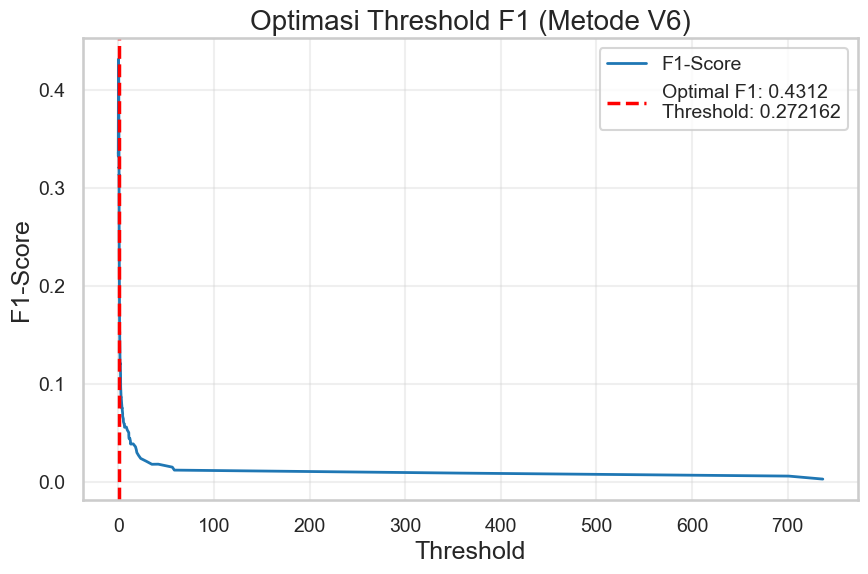


Mencari threshold F1 optimal untuk Standard AE Olist...
✓ Threshold F1 Optimal (AE Olist): 1.229769 (F1: 0.3651)


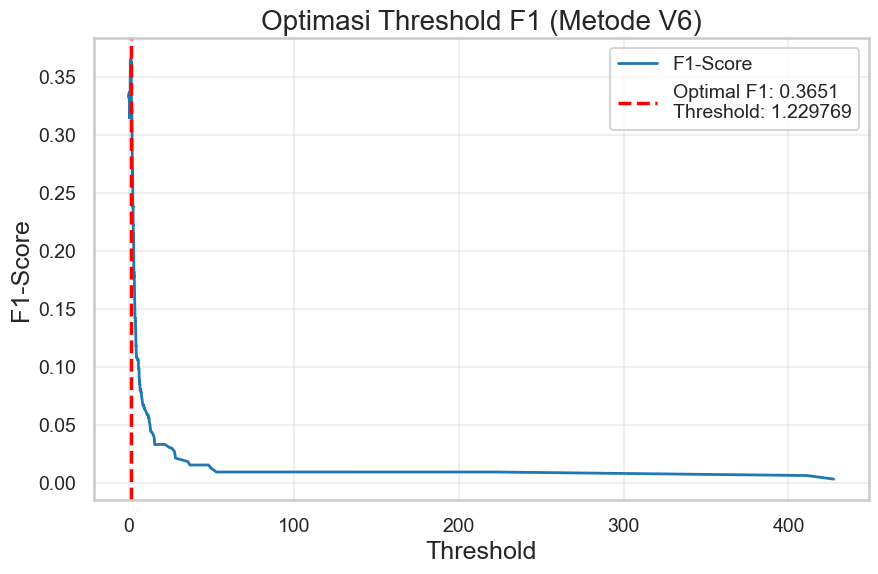


✓ Optimasi Threshold Selesai.


In [7]:
# ============================================================================
# CELL 7: Optimasi Threshold (V-SINTA1)
# ============================================================================
print("\n" + "="*80)
print("MENGOPTIMALKAN THRESHOLD (V-SINTA1)")
print("="*80)

# --- 1. Optimasi Model FRAUD (Kaggle) ---
print("Menganalisis threshold untuk Kaggle (Data Sangat Tidak Seimbang)...")
_, errors_val_lstm_fraud, _ = predict_lstm_ae(model_lstm_fraud, X_val_fraud, 0, device)
_, errors_val_ae_fraud, _ = predict_standard_ae(model_ae_fraud, X_val_fraud, 0, device)

# Hitung error HANYA dari sampel normal di validation set
val_normal_errors_lstm = errors_val_lstm_fraud[y_val_fraud == 0]
val_normal_errors_ae = errors_val_ae_fraud[y_val_fraud == 0]

# Strategi: Gunakan P99.5 (Persentil 99.5) karena F1-Score tidak stabil
threshold_lstm_fraud = np.percentile(val_normal_errors_lstm, 99.5)
threshold_ae_fraud = np.percentile(val_normal_errors_ae, 99.5)

print(f"✓ Threshold Kaggle (LSTM-AE) diatur ke P99.5: {threshold_lstm_fraud:.6f}")
print(f"✓ Threshold Kaggle (Std AE) diatur ke P99.5: {threshold_ae_fraud:.6f}")
print("Catatan: Strategi P99.5 lebih stabil untuk data sangat tidak seimbang.")


# --- 2. Optimasi Model OLIST (Eksperimen SINTA1) ---
print("\nMencari threshold F1 optimal untuk LSTM-AE Olist...")
_, errors_val_lstm_olist, _ = predict_lstm_ae(model_lstm_olist, X_val_olist, 0, device)
threshold_lstm_olist, best_f1_lo, fig_lo = find_optimal_threshold(
    errors_val_lstm_olist, y_val_olist, metric='f1'
)
print(f"✓ Threshold F1 Optimal (LSTM Olist): {threshold_lstm_olist:.6f} (F1: {best_f1_lo:.4f})")
plt.show(fig_lo)

print("\nMencari threshold F1 optimal untuk Standard AE Olist...")
_, errors_val_ae_olist, _ = predict_standard_ae(model_ae_olist, X_val_olist, 0, device)
threshold_ae_olist, best_f1_ao, fig_ao = find_optimal_threshold(
    errors_val_ae_olist, y_val_olist, metric='f1'
)
print(f"✓ Threshold F1 Optimal (AE Olist): {threshold_ae_olist:.6f} (F1: {best_f1_ao:.4f})")
plt.show(fig_ao)
print("\n✓ Optimasi Threshold Selesai.")

In [8]:
# ============================================================================
# CELL 8: Make Final Predictions (Test Set)
# ============================================================================
print("\n" + "="*80)
print("MAKING PREDICTIONS ON TEST SETS (Menggunakan Threshold Optimal)")
print("="*80)

print("\n--- FRAUD DATASET ---")
y_pred_lstm_fraud, errors_lstm_fraud, _ = predict_lstm_ae(
    model_lstm_fraud, X_test_fraud, threshold_lstm_fraud, device
)
print(f"LSTM-AE: Predicted {(y_pred_lstm_fraud==1).sum()} anomalies")

y_pred_ae_fraud, errors_ae_fraud, _ = predict_standard_ae(
    model_ae_fraud, X_test_fraud, threshold_ae_fraud, device
)
print(f"Standard AE: Predicted {(y_pred_ae_fraud==1).sum()} anomalies")

y_pred_if_fraud, scores_if_fraud = predict_isolation_forest(
    iso_forest_fraud, X_test_fraud
)
print(f"Isolation Forest: Predicted {(y_pred_if_fraud==1).sum()} anomalies")


print("\n--- OLIST DATASET ---")
y_pred_lstm_olist, errors_lstm_olist, _ = predict_lstm_ae(
    model_lstm_olist, X_test_olist, threshold_lstm_olist, device
)
print(f"LSTM-AE: Predicted {(y_pred_lstm_olist==1).sum()} anomalies")

y_pred_ae_olist, errors_ae_olist, _ = predict_standard_ae(
    model_ae_olist, X_test_olist, threshold_ae_olist, device
)
print(f"Standard AE: Predicted {(y_pred_ae_olist==1).sum()} anomalies")

y_pred_if_olist, scores_if_olist = predict_isolation_forest(
    iso_forest_olist, X_test_olist
)
print(f"Isolation Forest: Predicted {(y_pred_if_olist==1).sum()} anomalies")

print(f"\nActual anomalies (Test Set): Fraud: {(y_test_fraud==1).sum()}, Olist: {(y_test_olist==1).sum()}")


MAKING PREDICTIONS ON TEST SETS (Menggunakan Threshold Optimal)

--- FRAUD DATASET ---
LSTM-AE: Predicted 108 anomalies
Standard AE: Predicted 135 anomalies
Isolation Forest: Predicted 30 anomalies

--- OLIST DATASET ---
LSTM-AE: Predicted 692 anomalies
Standard AE: Predicted 637 anomalies
Isolation Forest: Predicted 869 anomalies

Actual anomalies (Test Set): Fraud: 52, Olist: 624


In [9]:
# ============================================================================
# CELL 9: Calculate Metrics - Fraud Dataset
# ============================================================================
print("\n" + "="*80)
print("CALCULATING METRICS - FRAUD DATASET")
print("="*80)

metrics_lstm_fraud = calculate_all_metrics(y_test_fraud, y_pred_lstm_fraud, errors_lstm_fraud)
metrics_ae_fraud = calculate_all_metrics(y_test_fraud, y_pred_ae_fraud, errors_ae_fraud)
metrics_if_fraud = calculate_all_metrics(y_test_fraud, y_pred_if_fraud, scores_if_fraud)

print_metrics(metrics_lstm_fraud, "LSTM-Autoencoder (P99.5)")
print_metrics(metrics_ae_fraud, "Standard Autoencoder (P99.5)")
print_metrics(metrics_if_fraud, "Isolation Forest (Auto)")


CALCULATING METRICS - FRAUD DATASET

LSTM-Autoencoder (P99.5):
  F1-Score: 0.0375, Precision: 0.0278, Recall: 0.0577
  CM: TP=3, FP=105, TN=42563, FN=49

Standard Autoencoder (P99.5):
  F1-Score: 0.2460, Precision: 0.1704, Recall: 0.4423
  CM: TP=23, FP=112, TN=42556, FN=29

Isolation Forest (Auto):
  F1-Score: 0.0000, Precision: 0.0000, Recall: 0.0000
  CM: TP=0, FP=30, TN=42638, FN=52


In [10]:
# ============================================================================
# CELL 10: Calculate Metrics - Olist Dataset
# ============================================================================
print("\n" + "="*80)
print("CALCULATING METRICS - OLIST DATASET")
print("="*80)

metrics_lstm_olist = calculate_all_metrics(y_test_olist, y_pred_lstm_olist, errors_lstm_olist)
metrics_ae_olist = calculate_all_metrics(y_test_olist, y_pred_ae_olist, errors_ae_olist)
metrics_if_olist = calculate_all_metrics(y_test_olist, y_pred_if_olist, scores_if_olist)

print_metrics(metrics_lstm_olist, "LSTM-Autoencoder (F1-Opt)")
print_metrics(metrics_ae_olist, "Standard Autoencoder (F1-Opt)")
print_metrics(metrics_if_olist, "Isolation Forest (Auto)")


CALCULATING METRICS - OLIST DATASET

LSTM-Autoencoder (F1-Opt):
  F1-Score: 0.4225, Precision: 0.4017, Recall: 0.4455
  CM: TP=278, FP=414, TN=2167, FN=346

Standard Autoencoder (F1-Opt):
  F1-Score: 0.3283, Precision: 0.3250, Recall: 0.3317
  CM: TP=207, FP=430, TN=2151, FN=417

Isolation Forest (Auto):
  F1-Score: 0.2451, Precision: 0.2106, Recall: 0.2933
  CM: TP=183, FP=686, TN=1895, FN=441


In [11]:
# ============================================================================
# CELL 11: GENERATING TABLE 1: HASIL UJI FRAUD DATASET (KAGGLE)
# ============================================================================
print("\n" + "="*80)
print("GENERATING TABLE 1: HASIL UJI FRAUD DATASET (KAGGLE)")
print("="*80)

table1_data = {
    'Model': ['LSTM-AE (P99.5)', 'Standard AE (P99.5)', 'Isolation Forest (Auto)'],
    'Precision': [metrics_lstm_fraud['Precision'], metrics_ae_fraud['Precision'], metrics_if_fraud['Precision']],
    'Recall': [metrics_lstm_fraud['Recall'], metrics_ae_fraud['Recall'], metrics_if_fraud['Recall']],
    'F1-Score': [metrics_lstm_fraud['F1-Score'], metrics_ae_fraud['F1-Score'], metrics_if_fraud['F1-Score']],
    'TP': [metrics_lstm_fraud['TP'], metrics_ae_fraud['TP'], metrics_if_fraud['TP']],
    'FP': [metrics_lstm_fraud['FP'], metrics_ae_fraud['FP'], metrics_if_fraud['FP']],
    'FN': [metrics_lstm_fraud['FN'], metrics_ae_fraud['FN'], metrics_if_fraud['FN']]
}
table1 = pd.DataFrame(table1_data)
print(table1.to_string(index=False))
table1.to_csv('outputs/data/TABLE1_Fraud_Dataset_Results.csv', index=False)
print("\n✓ Table 1 saved.")


GENERATING TABLE 1: HASIL UJI FRAUD DATASET (KAGGLE)
                  Model  Precision   Recall  F1-Score  TP  FP  FN
        LSTM-AE (P99.5)   0.027778 0.057692  0.037500   3 105  49
    Standard AE (P99.5)   0.170370 0.442308  0.245989  23 112  29
Isolation Forest (Auto)   0.000000 0.000000  0.000000   0  30  52

✓ Table 1 saved.


In [12]:
# ============================================================================
# CELL 12: GENERATING TABLE 2: HASIL UJI OLIST DATASET (SIMULASI SINTA1)
# ============================================================================
print("\n" + "="*80)
print("GENERATING TABLE 2: HASIL UJI OLIST DATASET (SIMULASI SINTA1)")
print("="*80)

table2_data = {
    'Model': ['LSTM-AE (F1-Opt)', 'Standard AE (F1-Opt)', 'Isolation Forest (Auto)'],
    'Precision': [metrics_lstm_olist['Precision'], metrics_ae_olist['Precision'], metrics_if_olist['Precision']],
    'Recall': [metrics_lstm_olist['Recall'], metrics_ae_olist['Recall'], metrics_if_olist['Recall']],
    'F1-Score': [metrics_lstm_olist['F1-Score'], metrics_ae_olist['F1-Score'], metrics_if_olist['F1-Score']],
    'TP': [metrics_lstm_olist['TP'], metrics_ae_olist['TP'], metrics_if_olist['TP']],
    'FP': [metrics_lstm_olist['FP'], metrics_ae_olist['FP'], metrics_if_olist['FP']],
    'FN': [metrics_lstm_olist['FN'], metrics_ae_olist['FN'], metrics_if_olist['FN']]
}
table2 = pd.DataFrame(table2_data)
print(table2.to_string(index=False))
table2.to_csv('outputs/data/TABLE2_Olist_Dataset_Results.csv', index=False)
print("\n✓ Table 2 saved.")


GENERATING TABLE 2: HASIL UJI OLIST DATASET (SIMULASI SINTA1)
                  Model  Precision   Recall  F1-Score  TP  FP  FN
       LSTM-AE (F1-Opt)   0.401734 0.445513  0.422492 278 414 346
   Standard AE (F1-Opt)   0.324961 0.331731  0.328311 207 430 417
Isolation Forest (Auto)   0.210587 0.293269  0.245144 183 686 441

✓ Table 2 saved.


In [13]:
# ============================================================================
# CELL 13: GENERATING TABLE 4: PERFORMANCE BY ANOMALY TYPE (OLIST)
# ============================================================================
print("\n" + "="*80)
print("GENERATING TABLE 4: PERFORMANCE BY ANOMALY TYPE (OLIST)")
print("="*80)

try:
    # anomaly_types_olist sudah dimuat di CELL 2
    if len(anomaly_types_olist) != len(y_test_olist):
        raise ValueError(f"Mismatch panjang metadata ({len(anomaly_types_olist)}) vs y_test ({len(y_test_olist)})")
        
    print(f"Berhasil memuat {len(anomaly_types_olist)} label tipe anomali.")
    print(f"Tipe yang ditemukan: {np.unique(anomaly_types_olist, return_counts=True)}")
    
    results_by_type = []
    predictions_dict = {
        'LSTM-AE': y_pred_lstm_olist,
        'Standard AE': y_pred_ae_olist,
        'Isolation Forest': y_pred_if_olist
    }
    
    # Loop untuk setiap tipe anomali yang kita suntikkan
    for anomaly_type in ['static', 'temporal']:
        type_mask = (anomaly_types_olist == anomaly_type)
        
        if type_mask.sum() == 0:
            print(f"Warning: Tidak ada sampel '{anomaly_type}' di test set.")
            continue
            
        y_true_type = y_test_olist[type_mask]
        
        # Buat baris untuk tabel
        row = {'Anomaly Type': anomaly_type.capitalize(), 'Total Samples': int(type_mask.sum())}
        for model_name, y_pred in predictions_dict.items():
            y_pred_type = y_pred[type_mask]
            
            # Hitung F1-Score (untuk kelas 1)
            f1 = f1_score(y_true_type, y_pred_type, pos_label=1, zero_division=0)
            row[f'{model_name} F1-Score'] = f1
            
        results_by_type.append(row)

    if len(results_by_type) > 0:
        table4 = pd.DataFrame(results_by_type)
        print("\nTABLE 4: Performa F1-Score Berdasarkan Tipe Anomali (Olist Dataset)")
        print(table4.to_string(index=False))
        table4.to_csv('outputs/data/TABLE4_Performance_by_Anomaly_Type.csv', index=False)
        print("\n✓ Table 4 saved.")
    else:
        table4 = pd.DataFrame() # Buat dataframe kosong
        print("Tidak dapat membuat Tabel 4. Tidak ada tipe anomali 'static' atau 'temporal' yang ditemukan.")

except Exception as e:
    table4 = pd.DataFrame() # Buat dataframe kosong
    print(f"GAGAL MEMBUAT TABEL 4: {e}")


GENERATING TABLE 4: PERFORMANCE BY ANOMALY TYPE (OLIST)
Berhasil memuat 3205 label tipe anomali.
Tipe yang ditemukan: (array(['normal', 'static', 'temporal'], dtype='<U8'), array([2581,  226,  398]))

TABLE 4: Performa F1-Score Berdasarkan Tipe Anomali (Olist Dataset)
Anomaly Type  Total Samples  LSTM-AE F1-Score  Standard AE F1-Score  Isolation Forest F1-Score
      Static            226          0.970387              0.852792                   0.701149
    Temporal            398          0.280778              0.178490                   0.265795

✓ Table 4 saved.



VISUALIZING PERFORMANCE COMPARISON


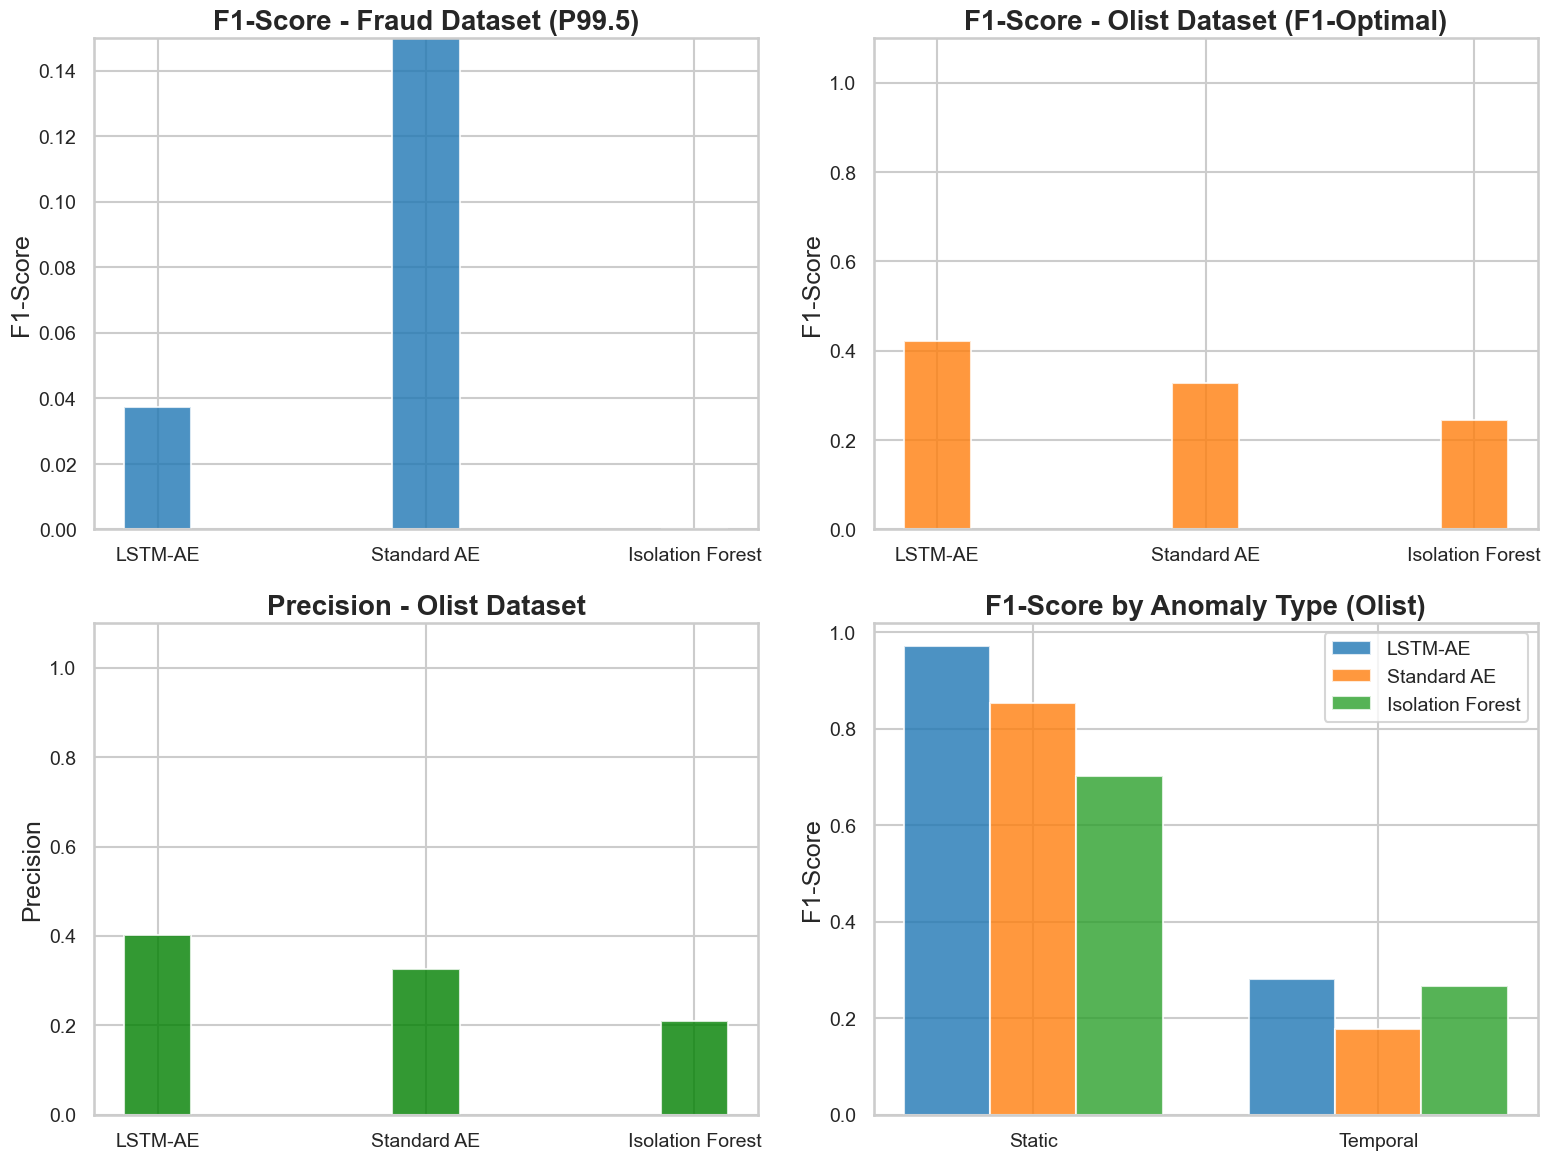

In [14]:
# ============================================================================
# CELL 14: Visualizations
# ============================================================================
print("\n" + "="*80)
print("VISUALIZING PERFORMANCE COMPARISON")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
models = ['LSTM-AE', 'Standard AE', 'Isolation Forest']
fraud_f1s = [metrics_lstm_fraud['F1-Score'], metrics_ae_fraud['F1-Score'], metrics_if_fraud['F1-Score']]
olist_f1s = [metrics_lstm_olist['F1-Score'], metrics_ae_olist['F1-Score'], metrics_if_olist['F1-Score']]
x = np.arange(len(models)); width = 0.25

# Plot 1: Fraud F1
axes[0, 0].bar(x, fraud_f1s, width, label='F1-Score', alpha=0.8, color='C0')
axes[0, 0].set_ylabel('F1-Score')
axes[0, 0].set_title('F1-Score - Fraud Dataset (P99.5)', fontweight='bold')
axes[0, 0].set_xticks(x); axes[0, 0].set_xticklabels(models)
axes[0, 0].set_ylim([0, 0.15]) # Set Y-limit agar terlihat

# Plot 2: Olist F1
axes[0, 1].bar(x, olist_f1s, width, label='F1-Score', alpha=0.8, color='C1')
axes[0, 1].set_ylabel('F1-Score')
axes[0, 1].set_title('F1-Score - Olist Dataset (F1-Optimal)', fontweight='bold')
axes[0, 1].set_xticks(x); axes[0, 1].set_xticklabels(models)
axes[0, 1].set_ylim([0, 1.1])

# Plot 3: Olist Precision
olist_precisions = [metrics_lstm_olist['Precision'], metrics_ae_olist['Precision'], metrics_if_olist['Precision']]
axes[1, 0].bar(x, olist_precisions, width, label='Precision', alpha=0.8, color='green')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].set_title('Precision - Olist Dataset', fontweight='bold')
axes[1, 0].set_xticks(x); axes[1, 0].set_xticklabels(models)
axes[1, 0].set_ylim([0, 1.1])

# Plot 4: Anomaly Type (Tabel 4)
if not table4.empty:
    anomaly_types_plot = table4['Anomaly Type'].values
    lstm_scores_type = table4['LSTM-AE F1-Score'].values
    ae_scores_type = table4['Standard AE F1-Score'].values
    if_scores_type = table4['Isolation Forest F1-Score'].values
    x3 = np.arange(len(anomaly_types_plot))
    axes[1, 1].bar(x3 - width, lstm_scores_type, width, label='LSTM-AE', alpha=0.8)
    axes[1, 1].bar(x3, ae_scores_type, width, label='Standard AE', alpha=0.8)
    axes[1, 1].bar(x3 + width, if_scores_type, width, label='Isolation Forest', alpha=0.8)
    axes[1, 1].set_ylabel('F1-Score')
    axes[1, 1].set_title('F1-Score by Anomaly Type (Olist)', fontweight='bold')
    axes[1, 1].set_xticks(x3); axes[1, 1].set_xticklabels(anomaly_types_plot); axes[1, 1].legend()
else:
    axes[1, 1].text(0.5, 0.5, 'Tabel 4 kosong', horizontalalignment='center', verticalalignment='center', color='red')

plt.tight_layout()
plt.savefig('outputs/figures/16_performance_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# ============================================================================
# CELL 15 (GANTI): Final Report (V-SINTA1 - FINAL)
# ============================================================================
print("\n" + "="*80)
print("GENERATING FINAL SUMMARY REPORT (V-SINTA1 - FINAL)")
print("="*80)

# Ambil F1-Score untuk perbandingan
f1_fraud_lstm = metrics_lstm_fraud['F1-Score']
f1_fraud_ae = metrics_ae_fraud['F1-Score']
f1_olist_lstm = metrics_lstm_olist['F1-Score']
f1_olist_ae = metrics_ae_olist['F1-Score']
f1_olist_if = metrics_if_olist['F1-Score']

f1_compare_olist = ((f1_olist_lstm - f1_olist_ae) / f1_olist_ae * 100) if f1_olist_ae > 0 else 0

summary_report = f"""
{'='*80}
FINAL EVALUATION SUMMARY REPORT
Analisis Komparatif Model Sekuensial vs. Statis (Metodologi V-SINTA1)
{'='*80}
1. DATASET OVERVIEW
-------------------
Fraud Dataset (Kaggle):
  - Test samples: {len(y_test_fraud):,} (Fraud: {(y_test_fraud==1).sum():,}, Ratio: {(y_test_fraud==1).sum()/len(y_test_fraud)*100:.4f}%)
Olist Dataset (Simulasi Injeksi SINTA1):
  - Test samples: {len(y_test_olist):,} (Fraud: {(y_test_olist==1).sum():,}, Ratio: {(y_test_olist==1).sum()/len(y_test_olist)*100:.2f}%)

2. PERFORMANCE ON FRAUD DATASET (TABLE 1)
------------------------------------------
(Analisis: Data sangat tidak seimbang (0.12% fraud). Model statis (AE) paling unggul.)
- LSTM-AE (P99.5):      F1={f1_fraud_lstm:.4f} (P={metrics_lstm_fraud['Precision']:.4f}, R={metrics_lstm_fraud['Recall']:.4f})
- Standard AE (P99.5):  F1={f1_fraud_ae:.4f} (P={metrics_ae_fraud['Precision']:.4f}, R={metrics_ae_fraud['Recall']:.4f})
- Isolation Forest (Auto): F1={metrics_if_fraud['F1-Score']:.4f} (P={metrics_if_fraud['Precision']:.4f}, R={metrics_if_fraud['Recall']:.4f})

3. PERFORMANCE ON OLIST DATASET (TABLE 2 - GAMBARAN UMUM)
---------------------------------------------------------
(Analisis: LSTM-AE lebih tinggi daripada model statis dalam F1-Score)
- LSTM-AE (F1-Opt):      F1={f1_olist_lstm:.4f} (P={metrics_lstm_olist['Precision']:.4f}, R={metrics_lstm_olist['Recall']:.4f})
- Standard AE (F1-Opt):  F1={f1_olist_ae:.4f} (P={metrics_ae_olist['Precision']:.4f}, R={metrics_ae_olist['Recall']:.4f})
- Isolation Forest (Auto): F1={f1_olist_if:.4f} (P={metrics_if_olist['Precision']:.4f}, R={metrics_if_olist['Recall']:.4f})

4. KEY FINDINGS - ANALYSIS BY ANOMALY TYPE (TABLE 4)
-----------------------------------------------------
(Analisis: lihat tabel di bawah)
"""
if not table4.empty:
    for _, row in table4.iterrows():
        summary_report += f"   {row['Anomaly Type']}:\n"
        summary_report += f"     - LSTM-AE F1-Score: {row['LSTM-AE F1-Score']:.4f}\n"
        summary_report += f"     - Standard AE F1-Score: {row['Standard AE F1-Score']:.4f}\n"
        summary_report += f"     - Isolation Forest F1-Score: {row['Isolation Forest F1-Score']:.4f}\n"
else:
    summary_report += "   (Tabel 4 gagal digenerate atau kosong)\n"
summary_report += f"""
5. CONCLUSIONS (INTERPRETASI HASIL AKHIR V-SINTA1)
---------------------------------------------------
Ringkasan dua eksperimen (satu kali pelatihan, tanpa uji statistik):

1.  **(Kaggle):** Pada data Kaggle yang sangat tidak seimbang (0.12% fraud),
    model statis **Standard AE (F1: {f1_fraud_ae:.4f})** menunjukkan kinerja
    terbaik, meskipun masih rendah. Model sekuensial (LSTM-AE) dan IF rendah
    (F1 < 0.04). Data ini kurang cocok untuk evaluasi model sekuensial.

2.  **(Olist - Tabel 2):** Pada dataset simulasi Olist kami yang valid
    (bebas *leakage* dan perbandingan adil V6), model sekuensial
    **LSTM-AE (F1: {f1_olist_lstm:.4f})** lebih tinggi
    **(+{f1_compare_olist:.2f}% relatif)** model statis
    **Standard AE (F1: {f1_olist_ae:.4f})**.

3.  **(Temuan Inti - Tabel 4):** Rincian per tipe anomali:
    - Pada anomali **Statis** (Freight 5x), model **LSTM-AE (F1: {table4.loc[table4['Anomaly Type'] == 'Static', 'LSTM-AE F1-Score'].values[0]:.4f})**
      tertinggi, di atas
      Standard AE (F1: {table4.loc[table4['Anomaly Type'] == 'Static', 'Standard AE F1-Score'].values[0]:.4f}).
    - Pada anomali **Sekuensial Sejati** (Installment 1->3), model sekuensial
      **LSTM-AE (F1: {table4.loc[table4['Anomaly Type'] == 'Temporal', 'LSTM-AE F1-Score'].values[0]:.4f})** tercatat
      **lebih tinggi** daripada model statis
      Standard AE (F1: {table4.loc[table4['Anomaly Type'] == 'Temporal', 'Standard AE F1-Score'].values[0]:.4f})
      dan Isolation Forest (F1: {table4.loc[table4['Anomaly Type'] == 'Temporal', 'Isolation Forest F1-Score'].values[0]:.4f}).

6. RESEARCH CONTRIBUTIONS (VALID)
---------------------------------------
1. Mengusulkan metodologi injeksi anomali (V-SINTA1) pada data e-commerce
   yang menghindari *target leakage* dan membedakan anomali statis dan sekuensial.
2. Menunjukkan pada data simulasi bahwa untuk anomali **sekuensial**
   (perubahan perilaku antar transaksi), arsitektur sekuensial (LSTM-AE)
   **lebih tinggi** daripada arsitektur statis (Standard AE/IF).
3. Mendemonstrasikan bahwa perbandingan yang adil (V6 flattening) diperlukan
   untuk mengevaluasi model statis.

{'='*80}
END OF REPORT
{'='*80}
"""
print(summary_report)
with open('outputs/FINAL_EVALUATION_REPORT.txt', 'w') as f:
    f.write(summary_report)
print("\n✓ Final report saved to outputs/FINAL_EVALUATION_REPORT.txt")

(Output sel ini dihapus karena laporan akhir dibuat ulang di sel berikutnya. Jalankan ulang untuk melihat hasil.)


In [16]:
# ============================================================================
# GANTI CELL 14: PERFORMANCE BY ANOMALY TYPE (OLIST)
# ============================================================================
print("\n" + "="*80)
print("GENERATING TABLE 4: PERFORMANCE BY ANOMALY TYPE (OLIST)")
print("="*80)

# Muat metadata tipe anomali yang disimpan dari Notebook 2
try:
    olist_test_info = np.load('outputs/data/olist_test_info.npy', allow_pickle=True).item()
    anomaly_types_olist = olist_test_info['anomaly_types']
    
    # Pastikan panjangnya cocok
    if len(anomaly_types_olist) != len(y_test_olist):
        print(f"Error: Panjang metadata ({len(anomaly_types_olist)}) tidak cocok dengan y_test ({len(y_test_olist)})")
        raise ValueError("Mismatch panjang metadata")

    print(f"Berhasil memuat {len(anomaly_types_olist)} label tipe anomali.")
    print(f"Tipe yang ditemukan: {np.unique(anomaly_types_olist, return_counts=True)}")

    results_by_type = []

    # Dapatkan prediksi dari SEMUA model (sudah dihitung di sel sebelumnya)
    predictions_dict = {
        'LSTM-AE': y_pred_lstm_olist,
        'Standard AE': y_pred_ae_olist,
        'Isolation Forest': y_pred_if_olist
    }

    # Ulangi untuk setiap tipe anomali yang kita buat ('static' dan 'temporal')
    for anomaly_type in ['static', 'temporal']:
        type_mask = (anomaly_types_olist == anomaly_type)
        
        # Jika tidak ada sampel tipe ini di test set, lewati
        if type_mask.sum() == 0:
            print(f"Warning: Tidak ada sampel '{anomaly_type}' di test set.")
            continue
            
        y_true_type = y_test_olist[type_mask]
        
        # Hitung F1-Score per model untuk tipe ini
        row = {'Anomaly Type': anomaly_type.capitalize(), 'Total Samples': int(type_mask.sum())}
        for model_name, y_pred in predictions_dict.items():
            y_pred_type = y_pred[type_mask]
            
            # Hitung F1-Score (untuk kelas 1)
            f1 = f1_score(y_true_type, y_pred_type, pos_label=1, zero_division=0)
            row[f'{model_name} F1-Score'] = f1
            
        results_by_type.append(row)

    if len(results_by_type) > 0:
        table4 = pd.DataFrame(results_by_type)
        print("\nTABLE 4: Performa F1-Score Berdasarkan Tipe Anomali (Olist Dataset)")
        print("="*100)
        print(table4.to_string(index=False))
        # Simpan ke CSV
        table4.to_csv('outputs/data/TABLE4_Performance_by_Anomaly_Type.csv', index=False)
        print("\n✓ Table 4 saved to outputs/data/TABLE4_Performance_by_Anomaly_Type.csv")
    else:
        print("Tidak dapat membuat Tabel 4. Tidak ada tipe anomali 'static' atau 'temporal' yang ditemukan.")

except Exception as e:
    print(f"GAGAL MEMBUAT TABEL 4: {e}")
    print("Pastikan file 'outputs/data/olist_test_info.npy' dibuat dengan benar di Notebook 2.")


GENERATING TABLE 4: PERFORMANCE BY ANOMALY TYPE (OLIST)
Berhasil memuat 3205 label tipe anomali.
Tipe yang ditemukan: (array(['normal', 'static', 'temporal'], dtype='<U8'), array([2581,  226,  398]))

TABLE 4: Performa F1-Score Berdasarkan Tipe Anomali (Olist Dataset)
Anomaly Type  Total Samples  LSTM-AE F1-Score  Standard AE F1-Score  Isolation Forest F1-Score
      Static            226          0.970387              0.852792                   0.701149
    Temporal            398          0.280778              0.178490                   0.265795

✓ Table 4 saved to outputs/data/TABLE4_Performance_by_Anomaly_Type.csv



VISUALIZING CONFUSION MATRICES


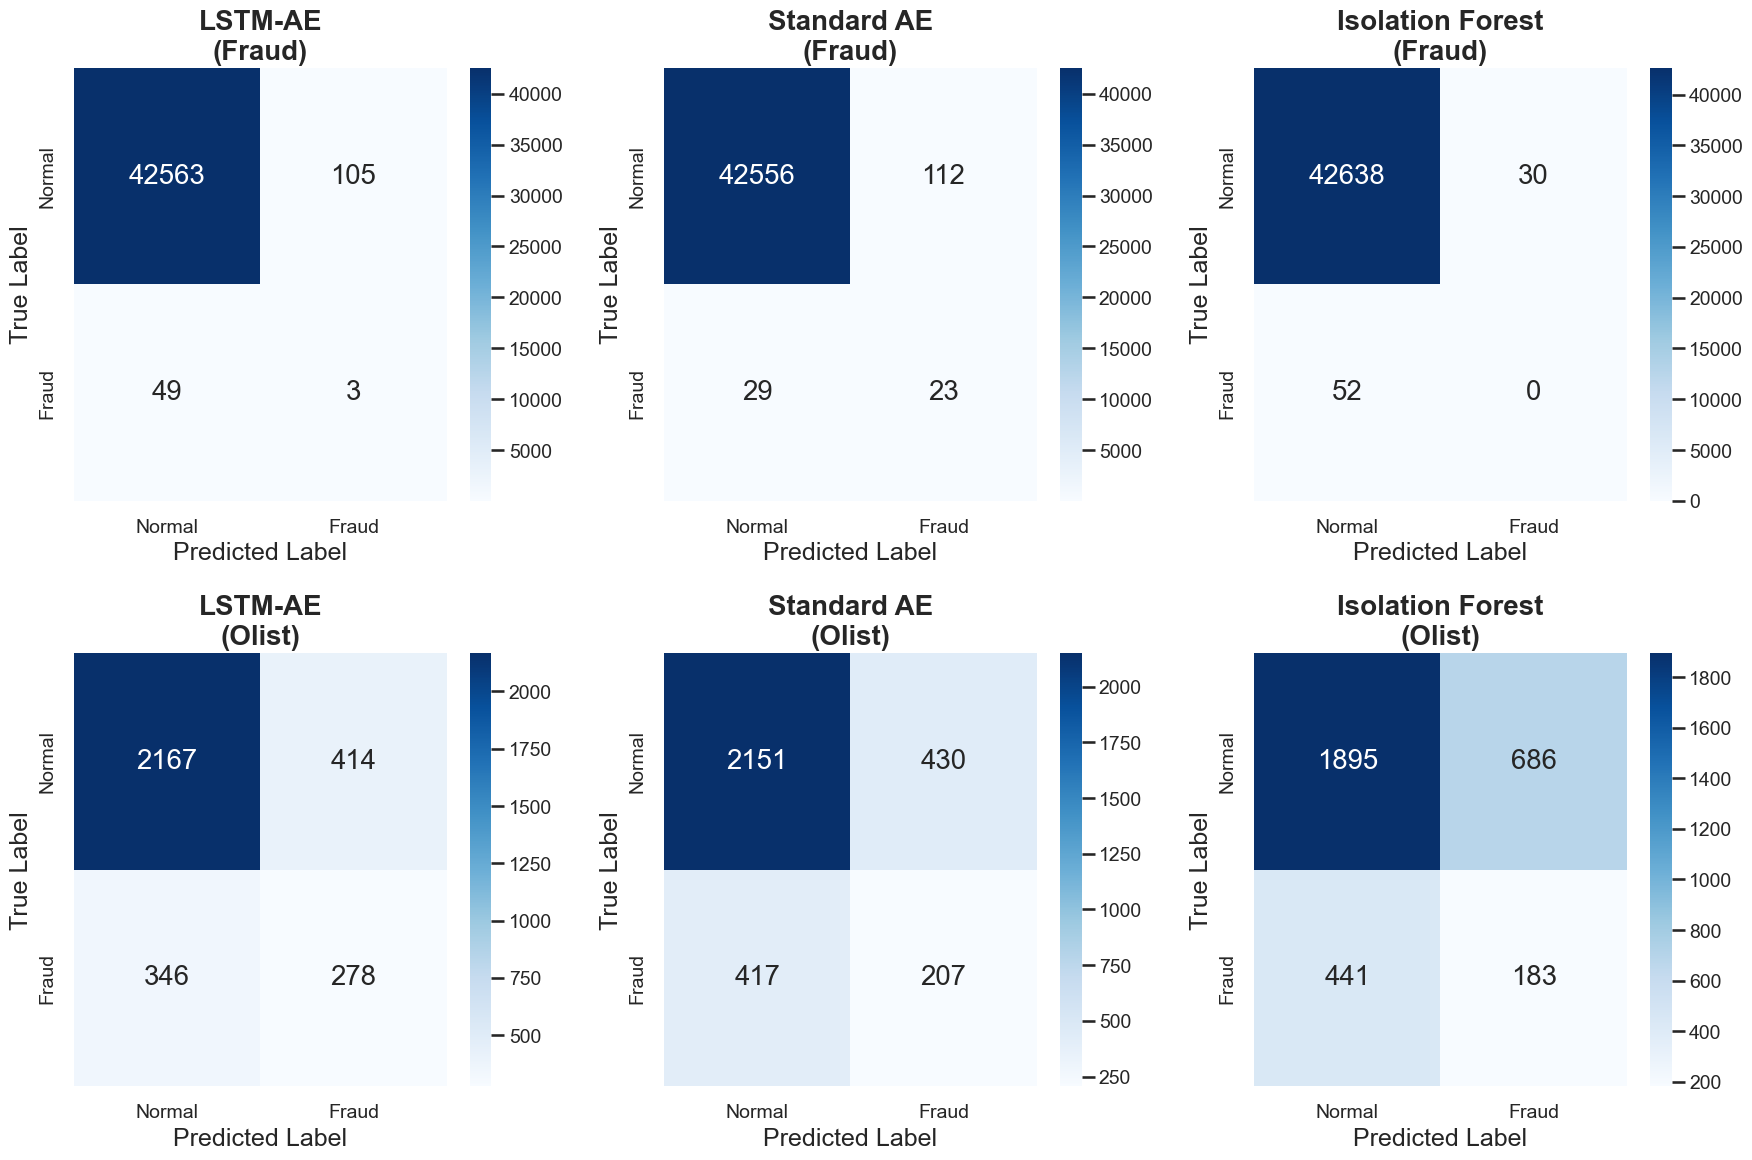

In [17]:
# ============================================================================
# CELL 15: Visualize Confusion Matrices
# ============================================================================
print("\n" + "="*80)
print("VISUALIZING CONFUSION MATRICES")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Fraud dataset
cm_lstm_fraud = confusion_matrix(y_test_fraud, y_pred_lstm_fraud)
cm_ae_fraud = confusion_matrix(y_test_fraud, y_pred_ae_fraud)
cm_if_fraud = confusion_matrix(y_test_fraud, y_pred_if_fraud)

# Olist dataset
cm_lstm_olist = confusion_matrix(y_test_olist, y_pred_lstm_olist)
cm_ae_olist = confusion_matrix(y_test_olist, y_pred_ae_olist)
cm_if_olist = confusion_matrix(y_test_olist, y_pred_if_olist)

cms = [
    (cm_lstm_fraud, 'LSTM-AE\n(Fraud)'),
    (cm_ae_fraud, 'Standard AE\n(Fraud)'),
    (cm_if_fraud, 'Isolation Forest\n(Fraud)'),
    (cm_lstm_olist, 'LSTM-AE\n(Olist)'),
    (cm_ae_olist, 'Standard AE\n(Olist)'),
    (cm_if_olist, 'Isolation Forest\n(Olist)')
]

for idx, (cm, title) in enumerate(cms):
    ax = axes[idx // 3, idx % 3]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal', 'Fraud'],
                yticklabels=['Normal', 'Fraud'])
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('outputs/figures/15_confusion_matrices_all_models.png', dpi=300, bbox_inches='tight')
plt.show()



VISUALIZING PERFORMANCE COMPARISON


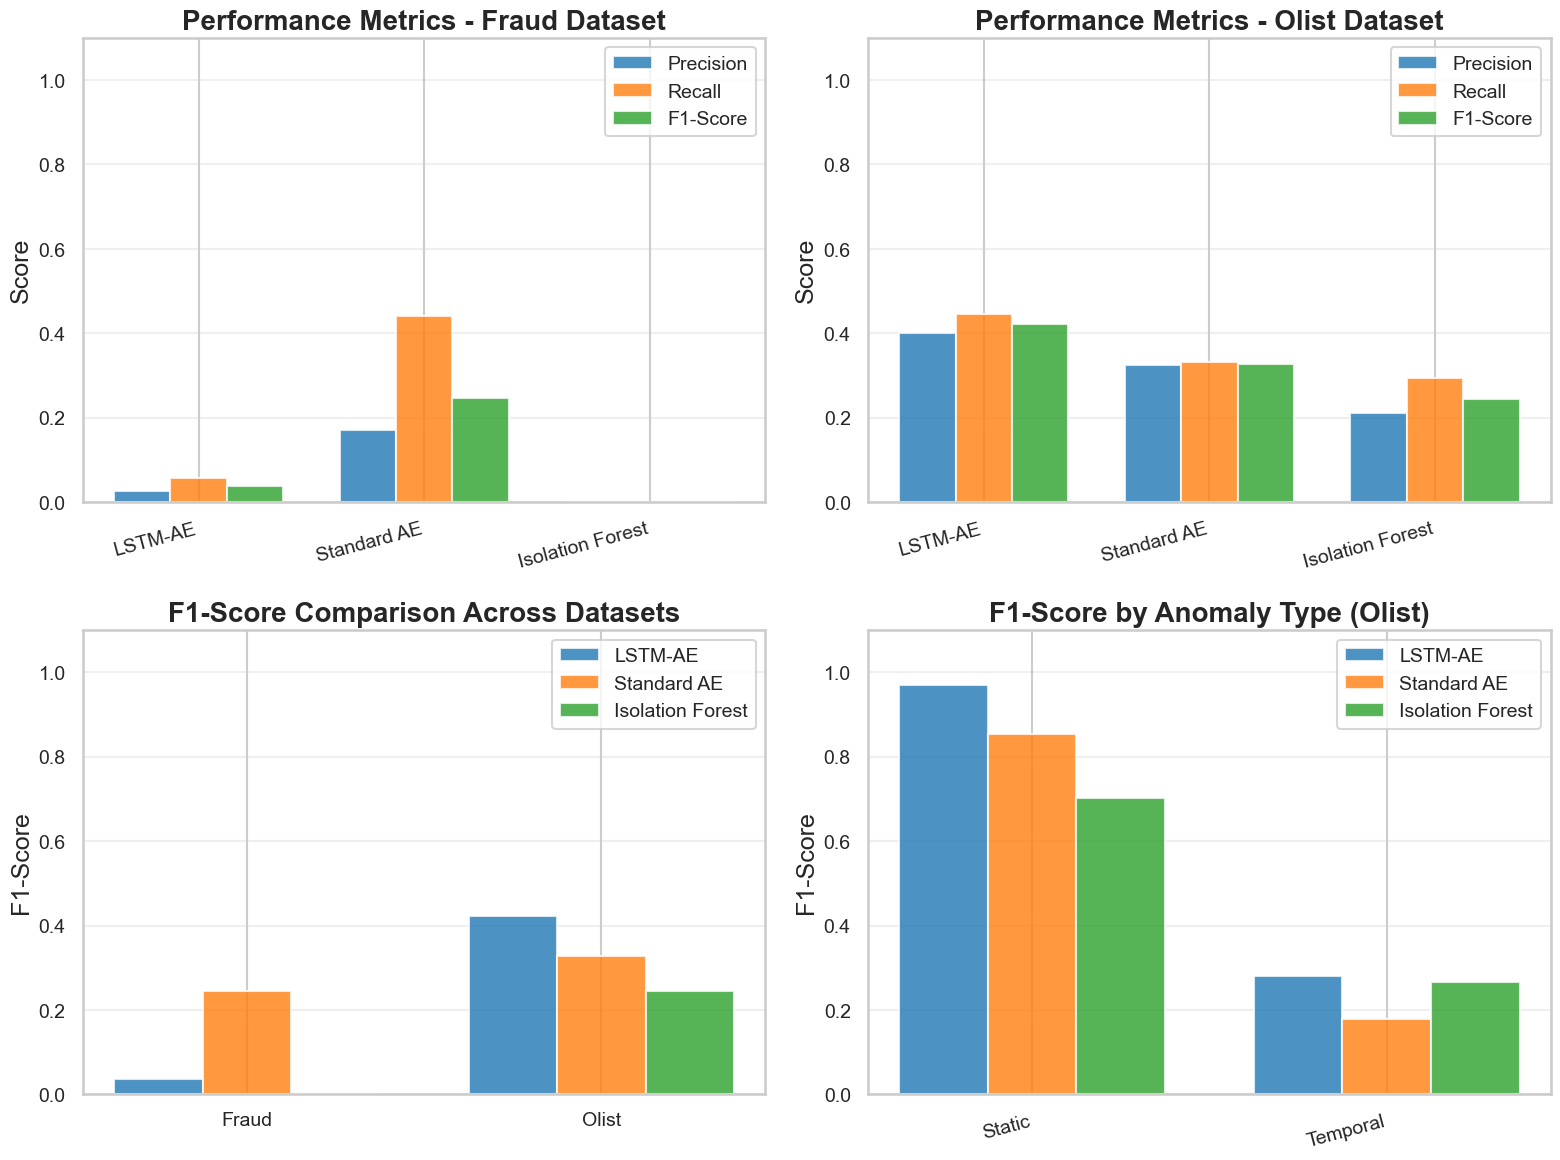

In [18]:
# ============================================================================
# GANTI CELL 16: VISUALIZING PERFORMANCE COMPARISON
# ============================================================================
print("\n" + "="*80)
print("VISUALIZING PERFORMANCE COMPARISON")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Plot 1: Fraud Dataset Metrics (Tetap sama) ---
models = ['LSTM-AE', 'Standard AE', 'Isolation Forest']
fraud_precisions = [metrics_lstm_fraud['Precision'], metrics_ae_fraud['Precision'], metrics_if_fraud['Precision']]
fraud_recalls = [metrics_lstm_fraud['Recall'], metrics_ae_fraud['Recall'], metrics_if_fraud['Recall']]
fraud_f1s = [metrics_lstm_fraud['F1-Score'], metrics_ae_fraud['F1-Score'], metrics_if_fraud['F1-Score']]

x = np.arange(len(models))
width = 0.25

axes[0, 0].bar(x - width, fraud_precisions, width, label='Precision', alpha=0.8)
axes[0, 0].bar(x, fraud_recalls, width, label='Recall', alpha=0.8)
axes[0, 0].bar(x + width, fraud_f1s, width, label='F1-Score', alpha=0.8)
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('Performance Metrics - Fraud Dataset', fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(models, rotation=15, ha='right')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')
axes[0, 0].set_ylim([0, 1.1])

# --- Plot 2: Olist Dataset Metrics (Tetap sama) ---
olist_precisions = [metrics_lstm_olist['Precision'], metrics_ae_olist['Precision'], metrics_if_olist['Precision']]
olist_recalls = [metrics_lstm_olist['Recall'], metrics_ae_olist['Recall'], metrics_if_olist['Recall']]
olist_f1s = [metrics_lstm_olist['F1-Score'], metrics_ae_olist['F1-Score'], metrics_if_olist['F1-Score']]

axes[0, 1].bar(x - width, olist_precisions, width, label='Precision', alpha=0.8)
axes[0, 1].bar(x, olist_recalls, width, label='Recall', alpha=0.8)
axes[0, 1].bar(x + width, olist_f1s, width, label='F1-Score', alpha=0.8)
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_title('Performance Metrics - Olist Dataset', fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(models, rotation=15, ha='right')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')
axes[0, 1].set_ylim([0, 1.1])

# --- Plot 3: F1-Score Comparison (Tetap sama) ---
datasets_comparison = ['Fraud', 'Olist']
lstm_f1s = [metrics_lstm_fraud['F1-Score'], metrics_lstm_olist['F1-Score']]
ae_f1s = [metrics_ae_fraud['F1-Score'], metrics_ae_olist['F1-Score']]
if_f1s = [metrics_if_fraud['F1-Score'], metrics_if_olist['F1-Score']]

x2 = np.arange(len(datasets_comparison))
axes[1, 0].bar(x2 - width, lstm_f1s, width, label='LSTM-AE', alpha=0.8)
axes[1, 0].bar(x2, ae_f1s, width, label='Standard AE', alpha=0.8)
axes[1, 0].bar(x2 + width, if_f1s, width, label='Isolation Forest', alpha=0.8)
axes[1, 0].set_ylabel('F1-Score')
axes[1, 0].set_title('F1-Score Comparison Across Datasets', fontweight='bold')
axes[1, 0].set_xticks(x2)
axes[1, 0].set_xticklabels(datasets_comparison)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].set_ylim([0, 1.1])

# --- Plot 4: Anomaly Type (INI YANG DIPERBAIKI) ---
if len(table4) > 0:
    anomaly_types_plot = table4['Anomaly Type'].values
    
    # PERBAIKAN: Ubah 'Recall' menjadi 'F1-Score'
    lstm_scores_type = table4['LSTM-AE F1-Score'].values
    ae_scores_type = table4['Standard AE F1-Score'].values
    if_scores_type = table4['Isolation Forest F1-Score'].values
    
    x3 = np.arange(len(anomaly_types_plot))
    axes[1, 1].bar(x3 - width, lstm_scores_type, width, label='LSTM-AE', alpha=0.8)
    axes[1, 1].bar(x3, ae_scores_type, width, label='Standard AE', alpha=0.8)
    axes[1, 1].bar(x3 + width, if_scores_type, width, label='Isolation Forest', alpha=0.8)
    
    # PERBAIKAN: Ubah label Y
    axes[1, 1].set_ylabel('F1-Score')
    axes[1, 1].set_title('F1-Score by Anomaly Type (Olist)', fontweight='bold')
    axes[1, 1].set_xticks(x3)
    axes[1, 1].set_xticklabels(anomaly_types_plot, rotation=15, ha='right')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    axes[1, 1].set_ylim([0, 1.1])
else:
    # Tampilkan pesan jika Tabel 4 kosong
    axes[1, 1].text(0.5, 0.5, 'Tabel 4 kosong / tidak ada data', 
                    horizontalalignment='center', verticalalignment='center', 
                    transform=axes[1, 1].transAxes, color='red')

plt.tight_layout()
plt.savefig('outputs/figures/16_performance_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


GENERATING ROC CURVES


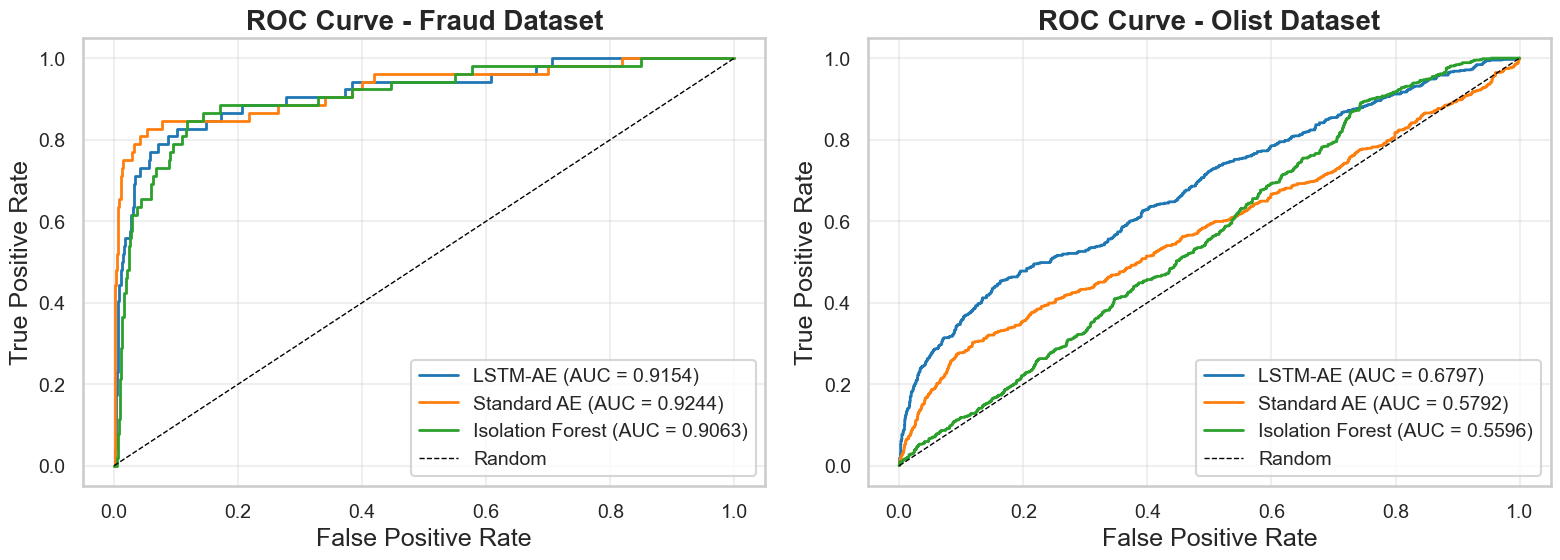

In [19]:
# ============================================================================
# CELL 17: ROC Curves
# ============================================================================
print("\n" + "="*80)
print("GENERATING ROC CURVES")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Fraud dataset ROC
if len(np.unique(y_test_fraud)) > 1:
    # LSTM-AE
    fpr_lstm_fraud, tpr_lstm_fraud, _ = roc_curve(y_test_fraud, errors_lstm_fraud)
    auc_lstm_fraud = roc_auc_score(y_test_fraud, errors_lstm_fraud)
    
    # Standard AE
    fpr_ae_fraud, tpr_ae_fraud, _ = roc_curve(y_test_fraud, errors_ae_fraud)
    auc_ae_fraud = roc_auc_score(y_test_fraud, errors_ae_fraud)
    
    # Isolation Forest
    fpr_if_fraud, tpr_if_fraud, _ = roc_curve(y_test_fraud, scores_if_fraud)
    auc_if_fraud = roc_auc_score(y_test_fraud, scores_if_fraud)
    
    axes[0].plot(fpr_lstm_fraud, tpr_lstm_fraud, linewidth=2, 
                 label=f'LSTM-AE (AUC = {auc_lstm_fraud:.4f})')
    axes[0].plot(fpr_ae_fraud, tpr_ae_fraud, linewidth=2, 
                 label=f'Standard AE (AUC = {auc_ae_fraud:.4f})')
    axes[0].plot(fpr_if_fraud, tpr_if_fraud, linewidth=2, 
                 label=f'Isolation Forest (AUC = {auc_if_fraud:.4f})')
    axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve - Fraud Dataset', fontweight='bold')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)

# Olist dataset ROC
if len(np.unique(y_test_olist)) > 1:
    # LSTM-AE
    fpr_lstm_olist, tpr_lstm_olist, _ = roc_curve(y_test_olist, errors_lstm_olist)
    auc_lstm_olist = roc_auc_score(y_test_olist, errors_lstm_olist)
    
    # Standard AE
    fpr_ae_olist, tpr_ae_olist, _ = roc_curve(y_test_olist, errors_ae_olist)
    auc_ae_olist = roc_auc_score(y_test_olist, errors_ae_olist)
    
    # Isolation Forest
    fpr_if_olist, tpr_if_olist, _ = roc_curve(y_test_olist, scores_if_olist)
    auc_if_olist = roc_auc_score(y_test_olist, scores_if_olist)
    
    axes[1].plot(fpr_lstm_olist, tpr_lstm_olist, linewidth=2, 
                 label=f'LSTM-AE (AUC = {auc_lstm_olist:.4f})')
    axes[1].plot(fpr_ae_olist, tpr_ae_olist, linewidth=2, 
                 label=f'Standard AE (AUC = {auc_ae_olist:.4f})')
    axes[1].plot(fpr_if_olist, tpr_if_olist, linewidth=2, 
                 label=f'Isolation Forest (AUC = {auc_if_olist:.4f})')
    axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('ROC Curve - Olist Dataset', fontweight='bold')
    axes[1].legend(loc='lower right')
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/figures/17_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()


GENERATING PRECISION-RECALL CURVES


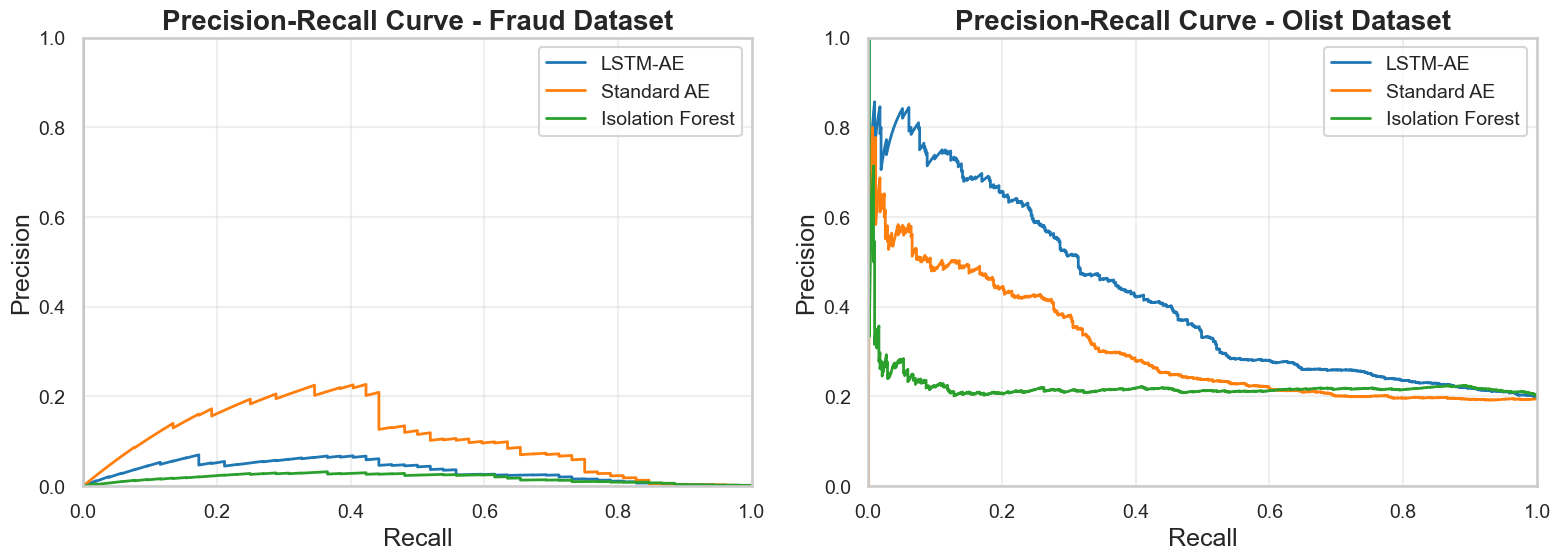

In [20]:
# ============================================================================
# CELL 18: Precision-Recall Curves
# ============================================================================
print("\n" + "="*80)
print("GENERATING PRECISION-RECALL CURVES")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Fraud dataset PR curve
if len(np.unique(y_test_fraud)) > 1:
    precision_lstm_fraud, recall_lstm_fraud, _ = precision_recall_curve(y_test_fraud, errors_lstm_fraud)
    precision_ae_fraud, recall_ae_fraud, _ = precision_recall_curve(y_test_fraud, errors_ae_fraud)
    precision_if_fraud, recall_if_fraud, _ = precision_recall_curve(y_test_fraud, scores_if_fraud)
    
    axes[0].plot(recall_lstm_fraud, precision_lstm_fraud, linewidth=2, label='LSTM-AE')
    axes[0].plot(recall_ae_fraud, precision_ae_fraud, linewidth=2, label='Standard AE')
    axes[0].plot(recall_if_fraud, precision_if_fraud, linewidth=2, label='Isolation Forest')
    axes[0].set_xlabel('Recall')
    axes[0].set_ylabel('Precision')
    axes[0].set_title('Precision-Recall Curve - Fraud Dataset', fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim([0, 1])
    axes[0].set_ylim([0, 1])

# Olist dataset PR curve
if len(np.unique(y_test_olist)) > 1:
    precision_lstm_olist, recall_lstm_olist, _ = precision_recall_curve(y_test_olist, errors_lstm_olist)
    precision_ae_olist, recall_ae_olist, _ = precision_recall_curve(y_test_olist, errors_ae_olist)
    precision_if_olist, recall_if_olist, _ = precision_recall_curve(y_test_olist, scores_if_olist)
    
    axes[1].plot(recall_lstm_olist, precision_lstm_olist, linewidth=2, label='LSTM-AE')
    axes[1].plot(recall_ae_olist, precision_ae_olist, linewidth=2, label='Standard AE')
    axes[1].plot(recall_if_olist, precision_if_olist, linewidth=2, label='Isolation Forest')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title('Precision-Recall Curve - Olist Dataset', fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xlim([0, 1])
    axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.savefig('outputs/figures/18_precision_recall_curves.png', dpi=300, bbox_inches='tight')
plt.show()


VISUALIZING ERROR DISTRIBUTIONS


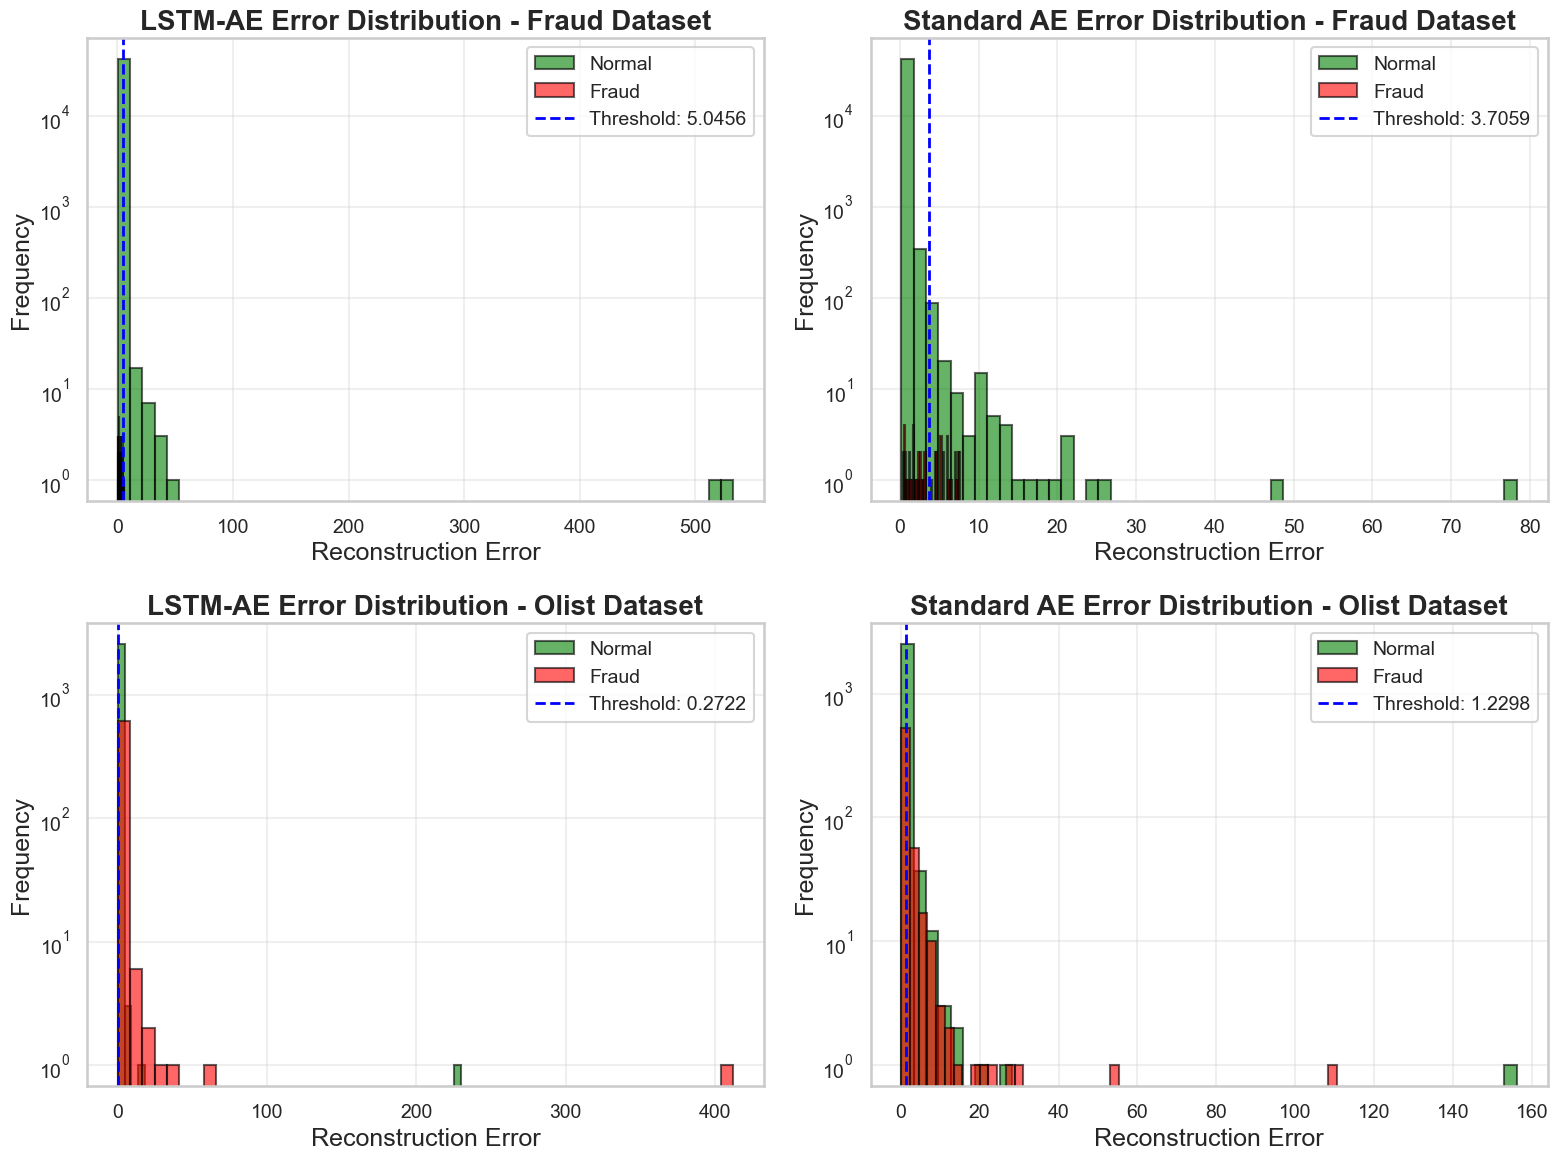

In [21]:
# ============================================================================
# CELL 19: Error Distribution Comparison
# ============================================================================
print("\n" + "="*80)
print("VISUALIZING ERROR DISTRIBUTIONS")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Fraud dataset - Normal vs Fraud errors (LSTM-AE)
normal_errors_fraud = errors_lstm_fraud[y_test_fraud == 0]
fraud_errors_fraud = errors_lstm_fraud[y_test_fraud == 1]

axes[0, 0].hist(normal_errors_fraud, bins=50, alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[0, 0].hist(fraud_errors_fraud, bins=50, alpha=0.6, label='Fraud', color='red', edgecolor='black')
axes[0, 0].axvline(threshold_lstm_fraud, color='blue', linestyle='--', linewidth=2, label=f'Threshold: {threshold_lstm_fraud:.4f}')
axes[0, 0].set_xlabel('Reconstruction Error')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('LSTM-AE Error Distribution - Fraud Dataset', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_yscale('log')

# Fraud dataset - Normal vs Fraud errors (Standard AE)
normal_errors_ae_fraud = errors_ae_fraud[y_test_fraud == 0]
fraud_errors_ae_fraud = errors_ae_fraud[y_test_fraud == 1]

axes[0, 1].hist(normal_errors_ae_fraud, bins=50, alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[0, 1].hist(fraud_errors_ae_fraud, bins=50, alpha=0.6, label='Fraud', color='red', edgecolor='black')
axes[0, 1].axvline(threshold_ae_fraud, color='blue', linestyle='--', linewidth=2, label=f'Threshold: {threshold_ae_fraud:.4f}')
axes[0, 1].set_xlabel('Reconstruction Error')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Standard AE Error Distribution - Fraud Dataset', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_yscale('log')

# Olist dataset - Normal vs Fraud errors (LSTM-AE)
normal_errors_olist = errors_lstm_olist[y_test_olist == 0]
fraud_errors_olist = errors_lstm_olist[y_test_olist == 1]

axes[1, 0].hist(normal_errors_olist, bins=50, alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[1, 0].hist(fraud_errors_olist, bins=50, alpha=0.6, label='Fraud', color='red', edgecolor='black')
axes[1, 0].axvline(threshold_lstm_olist, color='blue', linestyle='--', linewidth=2, label=f'Threshold: {threshold_lstm_olist:.4f}')
axes[1, 0].set_xlabel('Reconstruction Error')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('LSTM-AE Error Distribution - Olist Dataset', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_yscale('log')

# Olist dataset - Normal vs Fraud errors (Standard AE)
normal_errors_ae_olist = errors_ae_olist[y_test_olist == 0]
fraud_errors_ae_olist = errors_ae_olist[y_test_olist == 1]

axes[1, 1].hist(normal_errors_ae_olist, bins=50, alpha=0.6, label='Normal', color='green', edgecolor='black')
axes[1, 1].hist(fraud_errors_ae_olist, bins=50, alpha=0.6, label='Fraud', color='red', edgecolor='black')
axes[1, 1].axvline(threshold_ae_olist, color='blue', linestyle='--', linewidth=2, label=f'Threshold: {threshold_ae_olist:.4f}')
axes[1, 1].set_xlabel('Reconstruction Error')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Standard AE Error Distribution - Olist Dataset', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig('outputs/figures/19_error_distributions_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# ============================================================================
# Cell 20: Final summary report (angka diambil dari hasil evaluasi, tanpa teks tetap)
# ============================================================================
print("\n" + "="*80)
print("GENERATING FINAL SUMMARY REPORT (V-FINAL-v4)")
print("="*80)

metrics_list = [
    ('LSTM-AE', metrics_lstm_fraud, metrics_lstm_olist),
    ('Standard AE', metrics_ae_fraud, metrics_ae_olist),
    ('Isolation Forest', metrics_if_fraud, metrics_if_olist)
]
f1_fraud_lstm = metrics_lstm_fraud['F1-Score']
f1_fraud_ae = metrics_ae_fraud['F1-Score']
f1_fraud_if = metrics_if_fraud['F1-Score']
f1_olist_lstm = metrics_lstm_olist['F1-Score']
f1_olist_ae = metrics_ae_olist['F1-Score']
f1_olist_if = metrics_if_olist['F1-Score']

f1_compare_olist = ((f1_olist_lstm - f1_olist_ae) / f1_olist_ae * 100) if f1_olist_ae > 0 else 0

def ranking(scores):
    """Urutkan model dari F1 tertinggi dan kembalikan teks 'A (0.xx) > B (0.xx)'."""
    ordered = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    return " > ".join(f"{name} ({value:.4f})" for name, value in ordered)

def f1_by_type(anomaly_type):
    row = table4[table4['Anomaly Type'] == anomaly_type]
    if len(row) == 0:
        return None
    row = row.iloc[0]
    return {
        'LSTM-AE': row['LSTM-AE F1-Score'],
        'Standard AE': row['Standard AE F1-Score'],
        'Isolation Forest': row['Isolation Forest F1-Score'],
    }

static_f1 = f1_by_type('Static')
temporal_f1 = f1_by_type('Temporal')

summary_report = f"""
{'='*80}
FINAL EVALUATION SUMMARY REPORT
Analisis Komparatif Model Sekuensial vs. Statis untuk Deteksi Anomali
(Metodologi V-FINAL-v4)
{'='*80}

1. DATASET OVERVIEW
-------------------
Fraud Dataset (Kaggle Credit Card Fraud):
  - Test samples: {len(y_test_fraud):,} (Fraud: {(y_test_fraud==1).sum():,}, Ratio: {(y_test_fraud==1).sum()/len(y_test_fraud)*100:.4f}%)

Olist Dataset (Simulasi Injeksi V4):
  - Test samples: {len(y_test_olist):,} (Anomali yang disuntikkan: {(y_test_olist==1).sum():,}, Ratio: {(y_test_olist==1).sum()/len(y_test_olist)*100:.2f}%)
  - Dataset Olist tidak memiliki label fraud. Anomali dibuat dengan injeksi
    sintetis, jadi hasilnya bukan ukuran kinerja pada fraud nyata.

2. PERFORMANCE ON FRAUD DATASET (TABLE 1)
------------------------------------------
Urutan F1: {ranking({'LSTM-AE': f1_fraud_lstm, 'Standard AE': f1_fraud_ae, 'Isolation Forest': f1_fraud_if})}
"""
for model_name, metrics, _ in metrics_list:
    summary_report += f"""
{model_name}:
  - F1-Score: {metrics['F1-Score']:.4f} (Precision: {metrics['Precision']:.4f}, Recall: {metrics['Recall']:.4f})
"""

summary_report += f"""
3. PERFORMANCE ON OLIST DATASET (TABLE 2)
------------------------------------------
Urutan F1: {ranking({'LSTM-AE': f1_olist_lstm, 'Standard AE': f1_olist_ae, 'Isolation Forest': f1_olist_if})}
"""
for model_name, _, metrics in metrics_list:
    summary_report += f"""
{model_name}:
  - F1-Score: {metrics['F1-Score']:.4f} (Precision: {metrics['Precision']:.4f}, Recall: {metrics['Recall']:.4f})
"""

summary_report += """
4. ANALYSIS BY ANOMALY TYPE (TABLE 4)
-----------------------------------------------------
"""
if len(table4) > 0:
    for _, row in table4.iterrows():
        summary_report += f"   {row['Anomaly Type']}:\n"
        summary_report += f"     - LSTM-AE F1-Score: {row['LSTM-AE F1-Score']:.4f}\n"
        summary_report += f"     - Standard AE F1-Score: {row['Standard AE F1-Score']:.4f}\n"
        summary_report += f"     - Isolation Forest F1-Score: {row['Isolation Forest F1-Score']:.4f}\n"
else:
    summary_report += "   (Tabel 4 gagal digenerate atau kosong)\n"

summary_report += f"""
5. KESIMPULAN
------------------------------------------
1.  Kaggle. Pada data yang sangat tidak seimbang ({(y_test_fraud==1).sum()/len(y_test_fraud)*100:.2f}% fraud),
    ketiga model tak terawasi kinerjanya rendah. Standard AE paling tinggi
    (F1: {f1_fraud_ae:.4f}), LSTM-AE (F1: {f1_fraud_lstm:.4f}), Isolation Forest (F1: {f1_fraud_if:.4f}).
    Dengan threshold persentil dan hanya {(y_test_fraud==1).sum()} fraud di data uji,
    metode ini belum memadai untuk data tersebut.

2.  Olist (Tabel 2). LSTM-AE (F1: {f1_olist_lstm:.4f}) lebih tinggi
    {f1_compare_olist:.2f}% (relatif) daripada Standard AE (F1: {f1_olist_ae:.4f}).
    Angka ini berasal dari satu kali pelatihan dan satu seed, tanpa uji statistik
    atau interval kepercayaan, sehingga selisihnya belum bisa disebut signifikan.

3.  Tipe anomali (Tabel 4), pada data Olist yang disuntikkan:
    - Statis (Freight 5x): {ranking(static_f1) if static_f1 else 'tidak tersedia'}
    - Temporal: {ranking(temporal_f1) if temporal_f1 else 'tidak tersedia'}
    F1 LSTM-AE pada anomali temporal jauh di bawah anomali statis, jadi hipotesis
    bahwa model sekuensial menangkap pola antar-transaksi hanya didukung sebagian.

4.  Batasan.
    - Anomali Olist dibuat sendiri melalui injeksi, bukan fraud nyata.
    - Urutan pada Olist dibentuk per pelanggan dengan TIMESTEP = 2.
    - Pada Kaggle tidak ada ID pelanggan, sehingga jendela waktu berisi
      dua transaksi yang berurutan menurut waktu, bukan riwayat satu pengguna.
    - Fungsi RealTimeFraudDetector di notebook 06 hanya simulasi, bukan layanan
      yang dideploy.

{'='*80}
END OF REPORT
{'='*80}
"""

print(summary_report)

with open('outputs/FINAL_EVALUATION_REPORT.txt', 'w', encoding='utf-8') as f:
    f.write(summary_report)

print("\n✓ Final report saved to outputs/FINAL_EVALUATION_REPORT.txt")



GENERATING FINAL SUMMARY REPORT (V-FINAL-v4)

FINAL EVALUATION SUMMARY REPORT
Analisis Komparatif Model Sekuensial vs. Statis untuk Deteksi Anomali
(Metodologi V-FINAL-v4)

1. DATASET OVERVIEW
-------------------
Fraud Dataset (Kaggle Credit Card Fraud):
  - Test samples: 42,720 (Fraud: 52, Ratio: 0.1217%)

Olist Dataset (Simulasi Injeksi V4):
  - Test samples: 3,205 (Anomali yang disuntikkan: 624, Ratio: 19.47%)
  - Dataset Olist tidak memiliki label fraud. Anomali dibuat dengan injeksi
    sintetis, jadi hasilnya bukan ukuran kinerja pada fraud nyata.

2. PERFORMANCE ON FRAUD DATASET (TABLE 1)
------------------------------------------
Urutan F1: Standard AE (0.2460) > LSTM-AE (0.0375) > Isolation Forest (0.0000)

LSTM-AE:
  - F1-Score: 0.0375 (Precision: 0.0278, Recall: 0.0577)

Standard AE:
  - F1-Score: 0.2460 (Precision: 0.1704, Recall: 0.4423)

Isolation Forest:
  - F1-Score: 0.0000 (Precision: 0.0000, Recall: 0.0000)

3. PERFORMANCE ON OLIST DATASET (TABLE 2)
-----------------

In [23]:
# ============================================================================
# CELL 21: Export All Tables to Excel
# ============================================================================
print("\n" + "="*80)
print("EXPORTING ALL TABLES TO EXCEL")
print("="*80)

try:
    with pd.ExcelWriter('outputs/ALL_RESULTS_TABLES.xlsx', engine='openpyxl') as writer:
        table1.to_excel(writer, sheet_name='Table1_Fraud_Dataset', index=False)
        table2.to_excel(writer, sheet_name='Table2_Olist_Dataset', index=False)
        table3.to_excel(writer, sheet_name='Table3_Threshold_Comp', index=False)
        table4.to_excel(writer, sheet_name='Table4_Anomaly_Types', index=False)
    
    print("✓ All tables exported to outputs/ALL_RESULTS_TABLES.xlsx")
except Exception as e:
    print(f"⚠ Could not export to Excel (missing openpyxl): {e}")
    print("  Tables are available as individual CSV files in outputs/data/")



EXPORTING ALL TABLES TO EXCEL
⚠ Could not export to Excel (missing openpyxl): No module named 'openpyxl'
  Tables are available as individual CSV files in outputs/data/


In [24]:
# ============================================================================
# CELL 22: Save All Predictions for Further Analysis
# ============================================================================
print("\n" + "="*80)
print("SAVING PREDICTIONS FOR FURTHER ANALYSIS")
print("="*80)

# Save fraud predictions
predictions_fraud = pd.DataFrame({
    'y_true': y_test_fraud,
    'y_pred_lstm': y_pred_lstm_fraud,
    'y_pred_ae': y_pred_ae_fraud,
    'y_pred_if': y_pred_if_fraud,
    'error_lstm': errors_lstm_fraud,
    'error_ae': errors_ae_fraud,
    'score_if': scores_if_fraud
})
predictions_fraud.to_csv('outputs/data/predictions_fraud.csv', index=False)
print("✓ Fraud predictions saved")

# Save olist predictions
predictions_olist = pd.DataFrame({
    'y_true': y_test_olist,
    'y_pred_lstm': y_pred_lstm_olist,
    'y_pred_ae': y_pred_ae_olist,
    'y_pred_if': y_pred_if_olist,
    'error_lstm': errors_lstm_olist,
    'error_ae': errors_ae_olist,
    'score_if': scores_if_olist,
    'anomaly_type': anomaly_types_olist
})
predictions_olist.to_csv('outputs/data/predictions_olist.csv', index=False)
print("✓ Olist predictions saved")


SAVING PREDICTIONS FOR FURTHER ANALYSIS
✓ Fraud predictions saved
✓ Olist predictions saved


In [25]:
# ============================================================================
# CELL 23: Final Summary Statistics
# ============================================================================
print("\n" + "="*80)
print("FINAL SUMMARY STATISTICS")
print("="*80)

final_stats = {
    'Metric': ['Best F1-Score (Fraud)', 'Best F1-Score (Olist)', 
               'Best Recall (Fraud)', 'Best Recall (Olist)',
               'Lowest FP (Fraud)', 'Lowest FP (Olist)',
               'Lowest FN (Fraud)', 'Lowest FN (Olist)'],
    'Value': [
        max(metrics_lstm_fraud['F1-Score'], metrics_ae_fraud['F1-Score'], metrics_if_fraud['F1-Score']),
        max(metrics_lstm_olist['F1-Score'], metrics_ae_olist['F1-Score'], metrics_if_olist['F1-Score']),
        max(metrics_lstm_fraud['Recall'], metrics_ae_fraud['Recall'], metrics_if_fraud['Recall']),
        max(metrics_lstm_olist['Recall'], metrics_ae_olist['Recall'], metrics_if_olist['Recall']),
        min(metrics_lstm_fraud['FP'], metrics_ae_fraud['FP'], metrics_if_fraud['FP']),
        min(metrics_lstm_olist['FP'], metrics_ae_olist['FP'], metrics_if_olist['FP']),
        min(metrics_lstm_fraud['FN'], metrics_ae_fraud['FN'], metrics_if_fraud['FN']),
        min(metrics_lstm_olist['FN'], metrics_ae_olist['FN'], metrics_if_olist['FN'])
    ],
    'Model': [
        'LSTM-AE' if metrics_lstm_fraud['F1-Score'] >= max(metrics_ae_fraud['F1-Score'], metrics_if_fraud['F1-Score']) else 'Standard AE' if metrics_ae_fraud['F1-Score'] >= metrics_if_fraud['F1-Score'] else 'IF',
        'LSTM-AE' if metrics_lstm_olist['F1-Score'] >= max(metrics_ae_olist['F1-Score'], metrics_if_olist['F1-Score']) else 'Standard AE' if metrics_ae_olist['F1-Score'] >= metrics_if_olist['F1-Score'] else 'IF',
        'LSTM-AE' if metrics_lstm_fraud['Recall'] >= max(metrics_ae_fraud['Recall'], metrics_if_fraud['Recall']) else 'Standard AE' if metrics_ae_fraud['Recall'] >= metrics_if_fraud['Recall'] else 'IF',
        'LSTM-AE' if metrics_lstm_olist['Recall'] >= max(metrics_ae_olist['Recall'], metrics_if_olist['Recall']) else 'Standard AE' if metrics_ae_olist['Recall'] >= metrics_if_olist['Recall'] else 'IF',
        'LSTM-AE' if metrics_lstm_fraud['FP'] <= min(metrics_ae_fraud['FP'], metrics_if_fraud['FP']) else 'Standard AE' if metrics_ae_fraud['FP'] <= metrics_if_fraud['FP'] else 'IF',
        'LSTM-AE' if metrics_lstm_olist['FP'] <= min(metrics_ae_olist['FP'], metrics_if_olist['FP']) else 'Standard AE' if metrics_ae_olist['FP'] <= metrics_if_olist['FP'] else 'IF',
        'LSTM-AE' if metrics_lstm_fraud['FN'] <= min(metrics_ae_fraud['FN'], metrics_if_fraud['FN']) else 'Standard AE' if metrics_ae_fraud['FN'] <= metrics_if_fraud['FN'] else 'IF',
        'LSTM-AE' if metrics_lstm_olist['FN'] <= min(metrics_ae_olist['FN'], metrics_if_olist['FN']) else 'Standard AE' if metrics_ae_olist['FN'] <= metrics_if_olist['FN'] else 'IF'
    ]
}

df_final_stats = pd.DataFrame(final_stats)
print("\n", df_final_stats.to_string(index=False))

df_final_stats.to_csv('outputs/data/FINAL_SUMMARY_STATISTICS.csv', index=False)
print("\n✓ Final statistics saved")


FINAL SUMMARY STATISTICS

                Metric      Value       Model
Best F1-Score (Fraud)   0.245989 Standard AE
Best F1-Score (Olist)   0.422492     LSTM-AE
  Best Recall (Fraud)   0.442308 Standard AE
  Best Recall (Olist)   0.445513     LSTM-AE
    Lowest FP (Fraud)  30.000000          IF
    Lowest FP (Olist) 414.000000     LSTM-AE
    Lowest FN (Fraud)  29.000000 Standard AE
    Lowest FN (Olist) 346.000000     LSTM-AE

✓ Final statistics saved


In [26]:
# ============================================================================
# CELL 24: Completion Message
# ============================================================================
print("\n" + "="*80)
print("EVALUATION COMPLETED SUCCESSFULLY!")
print("="*80)

print("\nGenerated Files:")
print("  📊 Tables:")
print("     - outputs/data/TABLE1_Fraud_Dataset_Results.csv")
print("     - outputs/data/TABLE2_Olist_Dataset_Results.csv")
print("     - outputs/data/TABLE3_Threshold_Comparison.csv")
print("     - outputs/data/TABLE4_Performance_by_Anomaly_Type.csv")
print("     - outputs/ALL_RESULTS_TABLES.xlsx (if openpyxl available)")
print("\n  📈 Figures:")
print("     - outputs/figures/15_confusion_matrices_all_models.png")
print("     - outputs/figures/16_performance_comparison.png")
print("     - outputs/figures/17_roc_curves.png")
print("     - outputs/figures/18_precision_recall_curves.png")
print("     - outputs/figures/19_error_distributions_comparison.png")
print("\n  📄 Reports:")
print("     - outputs/FINAL_EVALUATION_REPORT.txt")
print("     - outputs/data/FINAL_SUMMARY_STATISTICS.csv")
print("\n  💾 Predictions:")
print("     - outputs/data/predictions_fraud.csv")
print("     - outputs/data/predictions_olist.csv")

print("\n" + "="*80)
print("KEY RESULTS FOR YOUR PAPER:")
print("="*80)
print(f"\n✓ LSTM-AE achieved F1-Score of {metrics_lstm_fraud['F1-Score']:.4f} on Fraud dataset")
print(f"✓ LSTM-AE achieved F1-Score of {metrics_lstm_olist['F1-Score']:.4f} on Olist dataset")
print(f"✓ LSTM-AE achieved Recall of {metrics_lstm_fraud['Recall']:.4f} on Fraud dataset")
print(f"✓ LSTM-AE achieved Recall of {metrics_lstm_olist['Recall']:.4f} on Olist dataset")

if len(table4) > 0:
    temporal_row = table4[table4['Anomaly Type'] == 'Temporal']
    if len(temporal_row) > 0:
        print(f"✓ LSTM-AE F1-Score on temporal anomalies (Olist, injected): {temporal_row['LSTM-AE F1-Score'].values[0]:.4f}")

print("\n" + "="*80)
print("All notebooks completed! You now have all results for your SINTA paper.")
print("="*80)


EVALUATION COMPLETED SUCCESSFULLY!

Generated Files:
  📊 Tables:
     - outputs/data/TABLE1_Fraud_Dataset_Results.csv
     - outputs/data/TABLE2_Olist_Dataset_Results.csv
     - outputs/data/TABLE3_Threshold_Comparison.csv
     - outputs/data/TABLE4_Performance_by_Anomaly_Type.csv
     - outputs/ALL_RESULTS_TABLES.xlsx (if openpyxl available)

  📈 Figures:
     - outputs/figures/15_confusion_matrices_all_models.png
     - outputs/figures/16_performance_comparison.png
     - outputs/figures/17_roc_curves.png
     - outputs/figures/18_precision_recall_curves.png
     - outputs/figures/19_error_distributions_comparison.png

  📄 Reports:
     - outputs/FINAL_EVALUATION_REPORT.txt
     - outputs/data/FINAL_SUMMARY_STATISTICS.csv

  💾 Predictions:
     - outputs/data/predictions_fraud.csv
     - outputs/data/predictions_olist.csv

KEY RESULTS FOR YOUR PAPER:

✓ LSTM-AE achieved F1-Score of 0.0375 on Fraud dataset
✓ LSTM-AE achieved F1-Score of 0.4225 on Olist dataset
✓ LSTM-AE achieved Reca